In [ ]:
## environment setting
pip install requests openai

In [ ]:
## environment setting
%pip install --upgrade openai httpx Brotli

In [ ]:
%pip install --upgrade --force-reinstall httpx openai

In [ ]:
%pip show openai httpx httpx2 brotli

In [ ]:
%pip uninstall -y httpx2 httpx

In [ ]:
%pip install --no-cache-dir httpx==0.28.1

In [ ]:
from openai import OpenAI
import os

client = OpenAI(
    api_key=os.environ["OPENAI_API_KEY"],
    timeout=30,
    max_retries=2
)

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "user", "content": "Reply only: API working"}
    ]
)

print(response.choices[0].message.content)

In [ ]:
%pip install --upgrade --force-reinstall openai

In [ ]:
%pip install requests openai numpy openpyxl

In [ ]:
import sys
print(sys.executable)

In [ ]:
### Cell_1
### To be included in repository
#### duplicate entry corrected cell
## correction final cell to take care of character in cell 
# Queries exceeding Brave limits are shortened and audited.
# Dependencies: %pip install openpyxl requests openai
import os, re, json, time, math, random, shutil, hashlib, tempfile
from pathlib import Path
from getpass import getpass
from collections import defaultdict
from openpyxl import load_workbook, Workbook
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from openpyxl.styles import Font, PatternFill
from openai import OpenAI
import requests

# ========== USER SETTINGS ==========
INPUT_FILE = Path(r'C:\bruse_TEST\bruse_test_expanded.xlsx')
OUTPUT_FILE = Path(r'C:\bruse_TEST\bruse_Brave_Evaluated.xlsx')
MAX_QUERIES = 201  # 0=all; 201=pilot. Existing completed queries are skipped.
TOP_K = 10
MODEL = 'gpt-4o-mini'
CONDITIONS = ['common','bruse_query2','bruse_query4','bruse_query6','bruse_query_full']  # this is 201 full run all conditions
BRAVE_URL = 'https://api.search.brave.com/res/v1/web/search'
# Conservative limits (Brave documents a maximum of 400 characters / 50 words).
BRAVE_MAX_CHARS = 380
BRAVE_MAX_WORDS = 48

# ========== HELPERS ==========
def safe(v):
    if isinstance(v, str):
        return ILLEGAL_CHARACTERS_RE.sub('', v)[:32767]
    return v

def clean(v):
    return re.sub(r'\s+', ' ', safe(str(v or ''))).strip()

def save_atomic(wb, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(prefix='bruse_tmp_',suffix='.xlsx',dir=str(path.parent))
    os.close(fd)
    try:
        wb.save(tmp)
        # Validate ZIP and worksheets before replacing last good file.
        check = load_workbook(tmp,read_only=True)
        check.close()
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp): os.remove(tmp)

def with_retry(fn, attempts=5):
    for i in range(attempts):
        try:
            return fn()
        except requests.HTTPError as exc:
            status = exc.response.status_code if exc.response is not None else None
            # Client validation/auth errors will not improve by retrying.
            if status not in (408, 429) and not (status is not None and 500 <= status <= 599):
                raise
            if i == attempts - 1:
                raise
            retry_after = exc.response.headers.get('Retry-After') if exc.response is not None else None
            try:
                wait = min(120, max(0, float(retry_after))) if retry_after else min(60, 2**i + random.random())
            except ValueError:
                wait = min(60, 2**i + random.random())
            print(f'  HTTP {status}; retry {i+1}/{attempts} in {wait:.1f}s')
            time.sleep(wait)
        except Exception as exc:
            # Retry transient network/OpenAI errors, not local validation failures.
            if isinstance(exc, (ValueError, TypeError, KeyError, AttributeError)):
                raise
            if i == attempts - 1:
                raise
            wait = min(60, 2**i + random.random())
            print(f'  Network retry {i+1}/{attempts} in {wait:.1f}s: {str(exc)[:100]}')
            time.sleep(wait)

def prepare_brave_query(original, expanded):
    """Keep original terms first, then unique expansion tokens in source order.

    This is a deterministic transport constraint, not a new expansion algorithm.
    """
    original_tokens = clean(original).split()
    expanded_tokens = clean(expanded).split()
    tokens = []
    seen = set()
    for token in original_tokens + expanded_tokens:
        key = token.casefold()
        if key not in seen:
            tokens.append(token)
            seen.add(key)
    selected = []
    for token in tokens:
        candidate = ' '.join(selected + [token])
        if len(selected) >= BRAVE_MAX_WORDS or len(candidate) > BRAVE_MAX_CHARS:
            break
        selected.append(token)
    if not selected and tokens:
        raise ValueError('Original query first token exceeds Brave character limit')
    submitted = ' '.join(selected)
    if not submitted:
        raise ValueError('Empty query after normalization')
    # Never silently discard original terms.
    if len(selected) < len(dict.fromkeys(t.casefold() for t in original_tokens)):
        raise ValueError('Original query exceeds configured Brave limits; cannot preserve it')
    return submitted, len(selected) < len(tokens)

def brave_search(query, session):
    def fetch():
        r = session.get(BRAVE_URL, params={'q': query, 'count': TOP_K}, timeout=50)
        if r.status_code >= 400:
            print('  Brave HTTP', r.status_code, 'response:', r.text[:300])
        r.raise_for_status()
        return r.json()
    data = with_retry(fetch)
    return [{'rank': i, 'url': clean(x.get('url')), 'title': clean(x.get('title')),
             'snippet': clean(x.get('description'))}
            for i, x in enumerate(data.get('web', {}).get('results', [])[:TOP_K], 1)]

def judge(original, docs, client):
    """
    Judge unique search results in small batches.
    Retry incomplete responses.
    Never silently assign a relevance grade to a missing judgment.
    """
    if not docs:
        return {}

    BATCH_SIZE = 8
    MAX_ATTEMPTS = 4
    all_judgments = {}

    prompt = """
You are an independent information retrieval relevance assessor.

Judge each document ONLY against the original Roman Urdu
query, not against any expanded query.

Use only its title, snippet, and URL.

Relevance grades:
3 = Highly relevant: directly addresses the intended concept.
2 = Relevant: substantially related and useful.
1 = Marginally relevant: limited relationship.
0 = Not relevant: unrelated or misleading.

Roman Urdu can be ambiguous. Do not assume that phonetically
similar terms necessarily have the same meaning.

Return JSON:
{
  "judgments": [
    {"id": "1", "grade": 2, "reason": "Brief explanation"}
  ]
}

Return exactly one judgment for EVERY supplied document ID.
Use the IDs exactly as provided.
Do not invent additional IDs.
"""

    for start in range(0, len(docs), BATCH_SIZE):

        batch = docs[start:start + BATCH_SIZE]
        pending = {str(d["id"]): d for d in batch}

        for attempt in range(1, MAX_ATTEMPTS + 1):

            if not pending:
                break

            request_docs = list(pending.values())

            def call():
                return client.chat.completions.create(
                    model=MODEL,
                    temperature=0,
                    response_format={"type": "json_object"},
                    messages=[
                        {"role": "system", "content": prompt},
                        {
                            "role": "user",
                            "content": json.dumps(
                                {
                                    "original_query": original,
                                    "documents": request_docs
                                },
                                ensure_ascii=False
                            )
                        }
                    ]
                )

            response = with_retry(call)
            content = response.choices[0].message.content

            try:
                parsed = json.loads(content)
                returned = parsed.get("judgments", [])

                if not isinstance(returned, list):
                    returned = []

            except (ValueError, TypeError):
                returned = []

            accepted = 0

            for item in returned:

                if not isinstance(item, dict):
                    continue

                doc_id = str(item.get("id", "")).strip()

                # Ignore unknown or already accepted IDs.
                if doc_id not in pending:
                    continue

                try:
                    grade = int(item["grade"])
                except (KeyError, ValueError, TypeError):
                    continue

                if grade not in (0, 1, 2, 3):
                    continue

                reason = clean(item.get("reason", ""))

                all_judgments[doc_id] = (grade, reason)

                del pending[doc_id]
                accepted += 1

            if pending:
                print(
                    f"  Judge batch {start // BATCH_SIZE + 1}: "
                    f"{len(pending)} missing, "
                    f"retry {attempt}/{MAX_ATTEMPTS}"
                )

                if attempt < MAX_ATTEMPTS:
                    time.sleep(min(2 ** attempt, 10))

        if pending:
            raise ValueError(
                "LLM judgments still incomplete after retries. "
                "Missing IDs: " + ", ".join(pending.keys())
            )

    expected = {str(d["id"]) for d in docs}

    if set(all_judgments) != expected:
        raise ValueError(
            "Final judgment validation failed. "
            "No results will be saved for this query."
        )

    return all_judgments


def metrics(grades):
    g=(grades[:TOP_K]+[0]*TOP_K)[:TOP_K]
    dcg=sum((2**v-1)/math.log2(i+2) for i,v in enumerate(g))
    ideal=sorted(g,reverse=True)
    idcg=sum((2**v-1)/math.log2(i+2) for i,v in enumerate(ideal))
    binary=[int(v>=2) for v in g]
    rr=next((1/i for i,v in enumerate(binary,1) if v),0.0)
    return [dcg/idcg if idcg else 0.0,rr,sum(binary)/TOP_K,int(any(binary))]

# ========== LOAD SOURCE ==========
if not INPUT_FILE.is_file(): raise FileNotFoundError(INPUT_FILE)
source=load_workbook(INPUT_FILE,read_only=True,data_only=True)
ws=source.active
headers={clean(c.value).lower():c.column-1 for c in ws[1]}
missing=[c for c in CONDITIONS if c not in headers]
if missing: raise ValueError('Missing source columns: '+str(missing))
rows=[]
for row_num, vals in enumerate(ws.iter_rows(min_row=2,values_only=True),2):
    q={c:clean(vals[headers[c]]) for c in CONDITIONS}
    if not q['common']: continue
    rows.append((row_num,q))
    if MAX_QUERIES and len(rows)>=MAX_QUERIES: break
source.close()
print('Source rows selected:',len(rows))

# ========== EXISTING WORKBOOK / BACKUP ==========
if OUTPUT_FILE.exists():
    backup=OUTPUT_FILE.with_name(OUTPUT_FILE.stem+'_BACKUP_BEFORE_SAFE_RUN.xlsx')
    if not backup.exists():
        shutil.copy2(OUTPUT_FILE,backup)
        print('Backup created:',backup)
    wb=load_workbook(OUTPUT_FILE)
    detail=wb['Ranked_Results']; metric=wb['Per_Query_Metrics']
else:
    wb=Workbook(); detail=wb.active; detail.title='Ranked_Results'
    detail.append(['common','condition','expanded_query','brave_rank','url','title','snippet',
                   'llm_grade','relevance_label','judge_reason','input_excel_row','submitted_query','query_truncated'])
    metric=wb.create_sheet('Per_Query_Metrics')
    metric.append(['common','condition','nDCG@10','MRR@10','P@10','Success@10','retrieved_count','input_excel_row','submitted_query','query_truncated'])

# Resume by stable source-row IDs, not by common-word spelling.
# Repeated Roman Urdu words are valid independent input rows.
print('Existing metric records:', max(0, metric.max_row - 1))

# Add stable input row ID to both sheets (old data remains untouched).
def ensure_column(sheet,name):
    labels=[clean(c.value) for c in sheet[1]]
    if name not in labels: sheet.cell(1,len(labels)+1,name)
    return [clean(c.value) for c in sheet[1]].index(name)+1
id_detail=ensure_column(detail,'input_excel_row')
id_metric=ensure_column(metric,'input_excel_row')
submitted_detail=ensure_column(detail,'submitted_query')
truncated_detail=ensure_column(detail,'query_truncated')
submitted_metric=ensure_column(metric,'submitted_query')
truncated_metric=ensure_column(metric,'query_truncated')
# Map legacy completed words to their unique input row; safe for the pilot.
source_by_word=defaultdict(list)
for rn,q in rows: source_by_word[q['common']].append(rn)
for sh,col in [(detail,id_detail),(metric,id_metric)]:
    for r in range(2,sh.max_row+1):
        if sh.cell(r,col).value is None:
            word=clean(sh.cell(r,1).value)
            if len(source_by_word[word])==1:
                sh.cell(r,col,source_by_word[word][0])

completed_ids=set()
for vals in metric.iter_rows(min_row=2,values_only=True):
    if len(vals)>=id_metric and vals[id_metric-1] is not None:
        completed_ids.add(int(vals[id_metric-1]))
# A row is complete only when it has all five metric conditions.
# Legacy completed rows are retained as-is; new audit fields apply to new rows.
by_id=defaultdict(set)
for vals in metric.iter_rows(min_row=2,values_only=True):
    if len(vals)>=id_metric and vals[id_metric-1] is not None:
        by_id[int(vals[id_metric-1])].add(clean(vals[1]))
completed_ids={rn for rn,cs in by_id.items() if set(CONDITIONS)<=cs}
# Fail safely if existing records have no stable IDs or conflict with input.
missing_id_rows=[r for r in range(2,metric.max_row+1)
                 if metric.cell(r,id_metric).value is None]
if missing_id_rows:
    raise ValueError(f'{len(missing_id_rows)} legacy metric records lack row IDs; '
                     'manual reconciliation is required before resuming.')
source_rows={rn:q['common'] for rn,q in rows}
for r in range(2,metric.max_row+1):
    rid=int(metric.cell(r,id_metric).value)
    if rid in source_rows and clean(metric.cell(r,1).value)!=source_rows[rid]:
        raise ValueError(f'Existing row ID {rid} conflicts with source common word; stop safely.')
print('Fully completed source rows:',len(completed_ids))

if not os.environ.get('BRAVE_API_KEY'):
    os.environ['BRAVE_API_KEY']=getpass('Brave API key: ')
if not os.environ.get('OPENAI_API_KEY'):
    os.environ['OPENAI_API_KEY']=getpass('OpenAI API key: ')
client=OpenAI(api_key=os.environ['OPENAI_API_KEY'])
session=requests.Session()
session.headers.update({'Accept':'application/json',
                        'X-Subscription-Token':os.environ['BRAVE_API_KEY']})
labels={0:'Not relevant',1:'Marginally relevant',2:'Relevant',3:'Highly relevant'}

# ========== MAIN LOOP ==========
for pos,(row_id,queries) in enumerate(rows,1):
    original=queries['common']
    if row_id in completed_ids:
        print(f'[{pos}/{len(rows)}] SKIP completed row {row_id}: {original}')
        continue
    print(f'[{pos}/{len(rows)}] SEARCH row {row_id}: {original}')
    try:
        searches={}
        submitted={}
        truncated={}
        for condition in CONDITIONS:
            submitted[condition], truncated[condition] = prepare_brave_query(original, queries[condition])
            if truncated[condition]:
                print(f'  {condition}: limited to {len(submitted[condition])} chars / {len(submitted[condition].split())} words')
            searches[condition]=brave_search(submitted[condition],session)
            time.sleep(0.25)
        pooled={}
        for results in searches.values():
            for d in results:
                key=d['url']
                if key and key not in pooled:
                    pooled[key]={'id':str(len(pooled)+1),'url':key,
                                 'title':d['title'],'snippet':d['snippet']}
        judgments=judge(original,list(pooled.values()),client)
        detail_rows=[]; metric_rows=[]
        for condition in CONDITIONS:
            grades=[]
            for d in searches[condition]:
                entry=pooled.get(d['url'])
                if entry:
                    grade,reason=judgments[entry['id']]
                else:
                    grade,reason=0,'Missing URL'
                grades.append(grade)
                detail_rows.append([original,condition,queries[condition],d['rank'],
                                    d['url'],d['title'],d['snippet'],grade,
                                    labels[grade],reason,row_id,submitted[condition],truncated[condition]])
            metric_rows.append([original,condition,*metrics(grades),len(grades),row_id,
                                submitted[condition],truncated[condition]])
        # Validate every cell BEFORE writing; avoids partial append exceptions.
        detail_rows=[[safe(v) for v in row] for row in detail_rows]
        metric_rows=[[safe(v) for v in row] for row in metric_rows]
        # Preserve legacy column positions, append only audit columns.
        if (id_detail!=11 or id_metric!=8 or submitted_detail!=12 or
                truncated_detail!=13 or submitted_metric!=9 or truncated_metric!=10):
            raise ValueError('Unexpected output column structure; stopped safely')
        for row in detail_rows: detail.append(row)
        for row in metric_rows: metric.append(row)
        save_atomic(wb,OUTPUT_FILE)
        completed_ids.add(row_id)
        print(f'  SAVED row {row_id}; unique judged URLs={len(pooled)}')
    except Exception as exc:
        print(f'ERROR at row {row_id}: {type(exc).__name__}: {exc}')
        print('Last saved Excel and backup remain safe. Stop and rerun after correction.')
        raise

# ========== REBUILD COMPARISON (NO NEW API CALLS) ==========
if 'Comparison' in wb.sheetnames: del wb['Comparison']
summary=wb.create_sheet('Comparison')
summary.append(['condition','queries','mean_nDCG@10','mean_MRR@10','mean_P@10',
                'mean_Success@10','delta_nDCG_vs_common','delta_MRR_vs_common',
                'delta_P_vs_common','delta_Success_vs_common'])
records=defaultdict(dict)
for v in metric.iter_rows(min_row=2,values_only=True):
    if len(v)>=8 and v[7] is not None:
        records[int(v[7])][clean(v[1])]=list(v[2:6])
valid={i:d for i,d in records.items() if all(c in d for c in CONDITIONS)}
def avg(a): return sum(a)/len(a) if a else 0.0
base=[avg([d['common'][j] for d in valid.values()]) for j in range(4)]
for c in CONDITIONS:
    means=[avg([d[c][j] for d in valid.values()]) for j in range(4)]
    summary.append([c,len(valid),*means,*[means[j]-base[j] for j in range(4)]])
for sh in wb:
    sh.freeze_panes='A2'
    sh.auto_filter.ref=sh.dimensions
    for cell in sh[1]:
        cell.font=Font(bold=True,color='FFFFFF')
        cell.fill=PatternFill('solid',fgColor='17365D')
save_atomic(wb,OUTPUT_FILE)
print('DONE. Fully evaluated rows:',len(valid),'Output:',OUTPUT_FILE)
print('NOTE: nDCG here is condition-specific; shared-pool nDCG will be recalculated in statistical analysis.')


In [ ]:
### Cell_2
###To be included in repository
#### bruse_query2 only calculation due to $$$
## correction final cell to take care of character in cell 
# BRUE PHASE II 
# Pilot workbook is read-only; Phase II is saved in a separate workbook.
# Pilot rows are excluded by verified input_excel_row and five-condition completion.
# Queries exceeding Brave limits are shortened
# Dependencies: %pip install openpyxl requests openai
import os, re, json, time, math, random, shutil, hashlib, tempfile
from pathlib import Path
from getpass import getpass
from collections import defaultdict
from openpyxl import load_workbook, Workbook
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from openpyxl.styles import Font, PatternFill
from openai import OpenAI
import requests

# ========== USER SETTINGS ==========
INPUT_FILE = Path(r'D:\BRUSE_TEST\BRUSE_test_expanded.xlsx')
PILOT_FILE = Path(r'D:\BRUSE_TEST\BRUSE_Brave_Evaluated.xlsx')  # READ ONLY; five-condition pilot
OUTPUT_FILE = Path(r'D:\BRUSE_TEST\BRUSE_Phase2_Common_vs_Query2.xlsx')  # separate Phase II


MAX_QUERIES = 0  # 0=all; 5=pilot. Existing completed queries are skipped.
TOP_K = 10
MODEL = 'gpt-4o-mini'
CONDITIONS = ['common','bruse_query2']
PILOT_CONDITIONS = {'common','bruse_query2','bruse_query4','bruse_query6','bruse_query_full'}
BRAVE_URL = 'https://api.search.brave.com/res/v1/web/search'
# Conservative limits (Brave documents a maximum of 400 characters / 50 words).
BRAVE_MAX_CHARS = 380
BRAVE_MAX_WORDS = 48

# ========== HELPERS ==========
def safe(v):
    if isinstance(v, str):
        return ILLEGAL_CHARACTERS_RE.sub('', v)[:32767]
    return v

def clean(v):
    return re.sub(r'\s+', ' ', safe(str(v or ''))).strip()

def save_atomic(wb, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(prefix='bruse_tmp_',suffix='.xlsx',dir=str(path.parent))
    os.close(fd)
    try:
        wb.save(tmp)
        # Validate ZIP and worksheets before replacing last good file.
        check = load_workbook(tmp,read_only=True)
        check.close()
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp): os.remove(tmp)

def with_retry(fn, attempts=5):
    for i in range(attempts):
        try:
            return fn()
        except requests.HTTPError as exc:
            status = exc.response.status_code if exc.response is not None else None
            # Client validation/auth errors will not improve by retrying.
            if status not in (408, 429) and not (status is not None and 500 <= status <= 599):
                raise
            if i == attempts - 1:
                raise
            retry_after = exc.response.headers.get('Retry-After') if exc.response is not None else None
            try:
                wait = min(120, max(0, float(retry_after))) if retry_after else min(60, 2**i + random.random())
            except ValueError:
                wait = min(60, 2**i + random.random())
            print(f'  HTTP {status}; retry {i+1}/{attempts} in {wait:.1f}s')
            time.sleep(wait)
        except Exception as exc:
            # Retry transient network/OpenAI errors, not local validation failures.
            if isinstance(exc, (ValueError, TypeError, KeyError, AttributeError)):
                raise
            if i == attempts - 1:
                raise
            wait = min(60, 2**i + random.random())
            print(f'  Network retry {i+1}/{attempts} in {wait:.1f}s: {str(exc)[:100]}')
            time.sleep(wait)

def prepare_brave_query(original, expanded):
    """Keep original terms first, then unique expansion tokens in source order.

    This is a deterministic transport constraint, not a new expansion algorithm.
    """
    original_tokens = clean(original).split()
    expanded_tokens = clean(expanded).split()
    tokens = []
    seen = set()
    for token in original_tokens + expanded_tokens:
        key = token.casefold()
        if key not in seen:
            tokens.append(token)
            seen.add(key)
    selected = []
    for token in tokens:
        candidate = ' '.join(selected + [token])
        if len(selected) >= BRAVE_MAX_WORDS or len(candidate) > BRAVE_MAX_CHARS:
            break
        selected.append(token)
    if not selected and tokens:
        raise ValueError('Original query first token exceeds Brave character limit')
    submitted = ' '.join(selected)
    if not submitted:
        raise ValueError('Empty query after normalization')
    # Never silently discard original terms.
    if len(selected) < len(dict.fromkeys(t.casefold() for t in original_tokens)):
        raise ValueError('Original query exceeds configured Brave limits; cannot preserve it')
    return submitted, len(selected) < len(tokens)

def brave_search(query, session):
    def fetch():
        r = session.get(BRAVE_URL, params={'q': query, 'count': TOP_K}, timeout=50)
        if r.status_code >= 400:
            print('  Brave HTTP', r.status_code, 'response:', r.text[:300])
        r.raise_for_status()
        return r.json()
    data = with_retry(fetch)
    return [{'rank': i, 'url': clean(x.get('url')), 'title': clean(x.get('title')),
             'snippet': clean(x.get('description'))}
            for i, x in enumerate(data.get('web', {}).get('results', [])[:TOP_K], 1)]

def judge(original, docs, client):
    """
    Judge unique search results in small batches.
    Retry incomplete responses.
    Never silently assign a relevance grade to a missing judgment.
    """
    if not docs:
        return {}

    BATCH_SIZE = 8
    MAX_ATTEMPTS = 4
    all_judgments = {}

    prompt = """
You are an independent information retrieval relevance assessor.

Judge each document ONLY against the original Roman Urdu
query, not against any expanded query.

Use only its title, snippet, and URL.

Relevance grades:
3 = Highly relevant: directly addresses the intended concept.
2 = Relevant: substantially related and useful.
1 = Marginally relevant: limited relationship.
0 = Not relevant: unrelated or misleading.

Roman Urdu can be ambiguous. Do not assume that phonetically
similar terms necessarily have the same meaning.

Return JSON:
{
  "judgments": [
    {"id": "1", "grade": 2, "reason": "Brief explanation"}
  ]
}

Return exactly one judgment for EVERY supplied document ID.
Use the IDs exactly as provided.
Do not invent additional IDs.
"""

    for start in range(0, len(docs), BATCH_SIZE):

        batch = docs[start:start + BATCH_SIZE]
        pending = {str(d["id"]): d for d in batch}

        for attempt in range(1, MAX_ATTEMPTS + 1):

            if not pending:
                break

            request_docs = list(pending.values())

            def call():
                return client.chat.completions.create(
                    model=MODEL,
                    temperature=0,
                    response_format={"type": "json_object"},
                    messages=[
                        {"role": "system", "content": prompt},
                        {
                            "role": "user",
                            "content": json.dumps(
                                {
                                    "original_query": original,
                                    "documents": request_docs
                                },
                                ensure_ascii=False
                            )
                        }
                    ]
                )

            response = with_retry(call)
            content = response.choices[0].message.content

            try:
                parsed = json.loads(content)
                returned = parsed.get("judgments", [])

                if not isinstance(returned, list):
                    returned = []

            except (ValueError, TypeError):
                returned = []

            accepted = 0

            for item in returned:

                if not isinstance(item, dict):
                    continue

                doc_id = str(item.get("id", "")).strip()

                # Ignore unknown or already accepted IDs.
                if doc_id not in pending:
                    continue

                try:
                    grade = int(item["grade"])
                except (KeyError, ValueError, TypeError):
                    continue

                if grade not in (0, 1, 2, 3):
                    continue

                reason = clean(item.get("reason", ""))

                all_judgments[doc_id] = (grade, reason)

                del pending[doc_id]
                accepted += 1

            if pending:
                print(
                    f"  Judge batch {start // BATCH_SIZE + 1}: "
                    f"{len(pending)} missing, "
                    f"retry {attempt}/{MAX_ATTEMPTS}"
                )

                if attempt < MAX_ATTEMPTS:
                    time.sleep(min(2 ** attempt, 10))

        if pending:
            raise ValueError(
                "LLM judgments still incomplete after retries. "
                "Missing IDs: " + ", ".join(pending.keys())
            )

    expected = {str(d["id"]) for d in docs}

    if set(all_judgments) != expected:
        raise ValueError(
            "Final judgment validation failed. "
            "No results will be saved for this query."
        )

    return all_judgments


def metrics(grades):
    g=(grades[:TOP_K]+[0]*TOP_K)[:TOP_K]
    dcg=sum((2**v-1)/math.log2(i+2) for i,v in enumerate(g))
    ideal=sorted(g,reverse=True)
    idcg=sum((2**v-1)/math.log2(i+2) for i,v in enumerate(ideal))
    binary=[int(v>=2) for v in g]
    rr=next((1/i for i,v in enumerate(binary,1) if v),0.0)
    return [dcg/idcg if idcg else 0.0,rr,sum(binary)/TOP_K,int(any(binary))]

# ========== LOAD SOURCE ==========
if not INPUT_FILE.is_file(): raise FileNotFoundError(INPUT_FILE)
source=load_workbook(INPUT_FILE,read_only=True,data_only=True)
ws=source.active
headers={clean(c.value).lower():c.column-1 for c in ws[1]}
missing=[c for c in CONDITIONS if c not in headers]
if missing: raise ValueError('Missing source columns: '+str(missing))
rows=[]
for row_num, vals in enumerate(ws.iter_rows(min_row=2,values_only=True),2):
    q={c:clean(vals[headers[c]]) for c in CONDITIONS}
    if not q['common']: continue
    rows.append((row_num,q))
    if MAX_QUERIES and len(rows)>=MAX_QUERIES: break
source.close()
print('Source rows selected:',len(rows))

# ========== READ-ONLY PILOT CHECKPOINT ==========
if not PILOT_FILE.is_file():
    raise FileNotFoundError(f'Pilot workbook not found: {PILOT_FILE}')
if PILOT_FILE.resolve() == OUTPUT_FILE.resolve():
    raise ValueError('Phase II output must differ from the pilot workbook')
pilot = load_workbook(PILOT_FILE, read_only=True, data_only=True)
if 'Per_Query_Metrics' not in pilot.sheetnames:
    raise ValueError('Pilot workbook lacks Per_Query_Metrics')
pilot_sheet = pilot['Per_Query_Metrics']
pilot_headers = {clean(c.value): i for i,c in enumerate(next(pilot_sheet.iter_rows(max_row=1)))}
if 'input_excel_row' not in pilot_headers:
    raise ValueError('Pilot workbook lacks input_excel_row; cannot skip safely')
pilot_by_id = defaultdict(set)
pilot_names = defaultdict(set)
for v in pilot_sheet.iter_rows(min_row=2, values_only=True):
    rid = v[pilot_headers['input_excel_row']]
    if rid is None:
        raise ValueError('Pilot metric record without input_excel_row; stop safely')
    rid = int(rid)
    pilot_by_id[rid].add(clean(v[pilot_headers['condition']]))
    pilot_names[rid].add(clean(v[pilot_headers['common']]))
pilot.close()
pilot_ids = {rid for rid, cs in pilot_by_id.items() if PILOT_CONDITIONS <= cs}
source_rows = {rn: q['common'] for rn,q in rows}
for rid in pilot_by_id:
    if rid in source_rows and pilot_names[rid] != {source_rows[rid]}:
        raise ValueError(f'Pilot row {rid} differs from input; stop safely')
    if rid in source_rows and rid not in pilot_ids:
        raise ValueError(f'Pilot row {rid} is partially completed; resolve in full experiment first')
print('Five-condition pilot rows protected:', len(pilot_ids))

# ========== INDEPENDENT PHASE II WORKBOOK ==========
if OUTPUT_FILE.exists():
    backup = OUTPUT_FILE.with_name(OUTPUT_FILE.stem + '_BACKUP_BEFORE_SAFE_RUN.xlsx')
    if not backup.exists():
        shutil.copy2(OUTPUT_FILE, backup)
        print('Phase II backup created:', backup)
    wb = load_workbook(OUTPUT_FILE)
    detail = wb['Ranked_Results']
    metric = wb['Per_Query_Metrics']
else:
    wb = Workbook()
    detail = wb.active
    detail.title = 'Ranked_Results'
    detail.append(['common','condition','expanded_query','brave_rank','url','title','snippet',
                   'llm_grade','relevance_label','judge_reason','input_excel_row',
                   'submitted_query','query_truncated'])
    metric = wb.create_sheet('Per_Query_Metrics')
    metric.append(['common','condition','nDCG@10','MRR@10','P@10','Success@10',
                   'retrieved_count','input_excel_row','submitted_query','query_truncated'])

expected_detail = ['common','condition','expanded_query','brave_rank','url','title','snippet',
                   'llm_grade','relevance_label','judge_reason','input_excel_row',
                   'submitted_query','query_truncated']
expected_metric = ['common','condition','nDCG@10','MRR@10','P@10','Success@10',
                   'retrieved_count','input_excel_row','submitted_query','query_truncated']
for sh, expected in ((detail,expected_detail),(metric,expected_metric)):
    actual = [clean(c.value) for c in sh[1]]
    if actual != expected:
        raise ValueError(f'Unexpected Phase II sheet structure: {sh.title}')

by_id = defaultdict(set)
for v in metric.iter_rows(min_row=2,values_only=True):
    if v[7] is None:
        raise ValueError('Phase II metric row missing input_excel_row')
    rid = int(v[7])
    if rid not in source_rows or clean(v[0]) != source_rows[rid]:
        raise ValueError(f'Phase II row {rid} does not match input')
    cond = clean(v[1])
    if cond not in CONDITIONS or cond in by_id[rid]:
        raise ValueError(f'Invalid or duplicate Phase II condition for row {rid}: {cond}')
    by_id[rid].add(cond)
if any(cs != set(CONDITIONS) for cs in by_id.values()):
    raise ValueError('Partial Phase II metrics detected; stop to prevent duplicate billing')
completed_ids = set(by_id) | pilot_ids
print('Phase II rows already completed:', len(by_id))
print('Remaining source rows:', sum(rid not in completed_ids for rid,_ in rows))

if not os.environ.get('BRAVE_API_KEY'):
    os.environ['BRAVE_API_KEY']=getpass('Brave API key: ')
if not os.environ.get('OPENAI_API_KEY'):
    os.environ['OPENAI_API_KEY']=getpass('OpenAI API key: ')
client=OpenAI(api_key=os.environ['OPENAI_API_KEY'])
session=requests.Session()
session.headers.update({'Accept':'application/json',
                        'X-Subscription-Token':os.environ['BRAVE_API_KEY']})
labels={0:'Not relevant',1:'Marginally relevant',2:'Relevant',3:'Highly relevant'}

# ========== MAIN LOOP ==========
for pos,(row_id,queries) in enumerate(rows,1):
    original=queries['common']
    if row_id in completed_ids:
        print(f'[{pos}/{len(rows)}] SKIP completed row {row_id}: {original}')
        continue
    print(f'[{pos}/{len(rows)}] SEARCH row {row_id}: {original}')
    try:
        searches={}
        submitted={}
        truncated={}
        for condition in CONDITIONS:
            submitted[condition], truncated[condition] = prepare_brave_query(original, queries[condition])
            if truncated[condition]:
                print(f'  {condition}: limited to {len(submitted[condition])} chars / {len(submitted[condition].split())} words')
            searches[condition]=brave_search(submitted[condition],session)
            time.sleep(0.25)
        pooled={}
        for results in searches.values():
            for d in results:
                key=d['url']
                if key and key not in pooled:
                    pooled[key]={'id':str(len(pooled)+1),'url':key,
                                 'title':d['title'],'snippet':d['snippet']}
        judgments=judge(original,list(pooled.values()),client)
        detail_rows=[]; metric_rows=[]
        for condition in CONDITIONS:
            grades=[]
            for d in searches[condition]:
                entry=pooled.get(d['url'])
                if entry:
                    grade,reason=judgments[entry['id']]
                else:
                    grade,reason=0,'Missing URL'
                grades.append(grade)
                detail_rows.append([original,condition,queries[condition],d['rank'],
                                    d['url'],d['title'],d['snippet'],grade,
                                    labels[grade],reason,row_id,submitted[condition],truncated[condition]])
            metric_rows.append([original,condition,*metrics(grades),len(grades),row_id,
                                submitted[condition],truncated[condition]])
        # Validate every cell BEFORE writing; avoids partial append exceptions.
        detail_rows=[[safe(v) for v in row] for row in detail_rows]
        metric_rows=[[safe(v) for v in row] for row in metric_rows]
        # Preserve legacy column positions, append only audit columns.
        for row in detail_rows: detail.append(row)
        for row in metric_rows: metric.append(row)
        save_atomic(wb,OUTPUT_FILE)
        completed_ids.add(row_id)
        print(f'  SAVED row {row_id}; unique judged URLs={len(pooled)}')
    except Exception as exc:
        print(f'ERROR at row {row_id}: {type(exc).__name__}: {exc}')
        print('Last saved Excel and backup remain safe. Stop and rerun after correction.')
        raise

# ========== REBUILD COMPARISON (NO NEW API CALLS) ==========
if 'Comparison' in wb.sheetnames: del wb['Comparison']
summary=wb.create_sheet('Comparison')
summary.append(['condition','queries','mean_nDCG@10','mean_MRR@10','mean_P@10',
                'mean_Success@10','delta_nDCG_vs_common','delta_MRR_vs_common',
                'delta_P_vs_common','delta_Success_vs_common'])
records=defaultdict(dict)
for v in metric.iter_rows(min_row=2,values_only=True):
    if len(v)>=8 and v[7] is not None:
        records[int(v[7])][clean(v[1])]=list(v[2:6])
valid={i:d for i,d in records.items() if all(c in d for c in CONDITIONS)}
def avg(a): return sum(a)/len(a) if a else 0.0
base=[avg([d['common'][j] for d in valid.values()]) for j in range(4)]
for c in CONDITIONS:
    means=[avg([d[c][j] for d in valid.values()]) for j in range(4)]
    summary.append([c,len(valid),*means,*[means[j]-base[j] for j in range(4)]])
for sh in wb:
    sh.freeze_panes='A2'
    sh.auto_filter.ref=sh.dimensions
    for cell in sh[1]:
        cell.font=Font(bold=True,color='FFFFFF')
        cell.fill=PatternFill('solid',fgColor='17365D')
save_atomic(wb,OUTPUT_FILE)
print('DONE. Phase II paired rows:',len(valid),'Output:',OUTPUT_FILE)
print('NOTE: nDCG here is condition-specific; shared-pool nDCG will be recalculated in statistical analysis.')


In [ ]:
### Cell_3
### to be included in repository
### qwen test final run from brave laptop###
### handl issue of empty column
# QWEN EXPANSION — BRAVE TOP-10 + GPT-4o-mini RELEVANCE EVALUATION
# pip install openpyxl requests openai
# No PILOT_FILE. This evaluates every source row, with resumable checkpoints.
import os, re, json, time, math, random, tempfile, hashlib, shutil
from pathlib import Path
from getpass import getpass
from collections import defaultdict
from openpyxl import load_workbook, Workbook
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from openpyxl.styles import Font, PatternFill
from openai import OpenAI
import requests

# ========== SETTINGS ==========
FOLDER = Path(r'D:\BORUE')
INPUT_FILE = FOLDER / 'qwen_expanded.xlsx'
OUTPUT_FILE = FOLDER / 'Qwen_Brave_Evaluated.xlsx'
MAX_QUERIES = 0  # Initial safety check. Change to 0 for ALL 2441 rows.
TOP_K = 10
MODEL = 'gpt-4o-mini'
CONDITION = 'qwen_expanded'
BRAVE_URL = 'https://api.search.brave.com/res/v1/web/search'
BRAVE_MAX_CHARS = 380
BRAVE_MAX_WORDS = 48
PROMPT_VERSION = 'bruse_RELEVANCE_ORIGINAL_V1'

# ========== HELPERS ==========
def safe(v):
    return ILLEGAL_CHARACTERS_RE.sub('', v)[:32767] if isinstance(v, str) else v

def clean(v):
    return re.sub(r'\s+', ' ', safe(str(v if v is not None else ''))).strip()

def fingerprint(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for part in iter(lambda: f.read(1024*1024), b''):
            h.update(part)
    return h.hexdigest()

def save_atomic(book, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(prefix='qwen_tmp_', suffix='.xlsx', dir=str(path.parent))
    os.close(fd)
    try:
        book.save(tmp)
        test = load_workbook(tmp, read_only=True)
        test.close()
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)

def with_retry(fn, attempts=5):
    for i in range(attempts):
        try:
            return fn()
        except requests.HTTPError as exc:
            status = exc.response.status_code if exc.response is not None else None
            if status not in (408, 429) and not (status is not None and 500 <= status <= 599):
                raise
            if i == attempts-1:
                raise
            hdr = exc.response.headers.get('Retry-After') if exc.response is not None else None
            try:
                wait = min(120, max(0, float(hdr))) if hdr else min(60, 2**i+random.random())
            except ValueError:
                wait = min(60, 2**i+random.random())
            print(f'  HTTP {status}; retrying in {wait:.1f}s')
            time.sleep(wait)
        except Exception as exc:
            if isinstance(exc, (ValueError, TypeError, KeyError, AttributeError)):
                raise
            if i == attempts-1:
                raise
            wait = min(60, 2**i+random.random())
            print(f'  Network/API retry in {wait:.1f}s: {str(exc)[:100]}')
            time.sleep(wait)

def prepare_brave_query(original, expanded):
    # Same transport procedure as bruse Phase II: original first,
    # followed by unique expansion tokens, in their original order.
    original_tokens = clean(original).split()
    expansion_tokens = clean(expanded).split()
    tokens, seen = [], set()
    for token in original_tokens + expansion_tokens:
        key = token.casefold()
        if key not in seen:
            tokens.append(token)
            seen.add(key)
    selected = []
    for token in tokens:
        candidate = ' '.join(selected + [token])
        if len(selected) >= BRAVE_MAX_WORDS or len(candidate) > BRAVE_MAX_CHARS:
            break
        selected.append(token)
    if not selected:
        raise ValueError('Empty Brave query')
    unique_original_count = len(dict.fromkeys(t.casefold() for t in original_tokens))
    if len(selected) < unique_original_count:
        raise ValueError('Cannot preserve complete original query within Brave limit')
    return ' '.join(selected), len(selected) < len(tokens)

def brave_search(query, session):
    def fetch():
        r = session.get(BRAVE_URL, params={'q':query, 'count':TOP_K}, timeout=50)
        if r.status_code >= 400:
            print('  Brave HTTP', r.status_code, r.text[:300])
        r.raise_for_status()
        return r.json()
    data = with_retry(fetch)
    return [dict(rank=i, url=clean(d.get('url')),
                 title=clean(d.get('title')), snippet=clean(d.get('description')))
            for i,d in enumerate(data.get('web',{}).get('results',[])[:TOP_K],1)]

# This is the same relevance rubric and JSON contract as the uploaded bruse code.
JUDGE_PROMPT = '''You are an independent information retrieval relevance assessor.

Judge each document ONLY against the original Roman Urdu
query, not against any expanded query.

Use only its title, snippet, and URL.

Relevance grades:
3 = Highly relevant: directly addresses the intended concept.
2 = Relevant: substantially related and useful.
1 = Marginally relevant: limited relationship.
0 = Not relevant: unrelated or misleading.

Roman Urdu can be ambiguous. Do not assume that phonetically
similar terms necessarily have the same meaning.

Return JSON:
{
  "judgments": [
    {"id": "1", "grade": 2, "reason": "Brief explanation"}
  ]
}

Return exactly one judgment for EVERY supplied document ID.
Use the IDs exactly as provided.
Do not invent additional IDs.'''

def judge(original, docs, client):
    if not docs:
        return {}
    BATCH_SIZE, MAX_ATTEMPTS = 8, 4
    all_judgments = {}
    for start in range(0,len(docs),BATCH_SIZE):
        batch = docs[start:start+BATCH_SIZE]
        pending = {str(d['id']):d for d in batch}
        for attempt in range(1,MAX_ATTEMPTS+1):
            if not pending:
                break
            request_docs = list(pending.values())
            def call():
                return client.chat.completions.create(
                    model=MODEL, temperature=0,
                    response_format={'type':'json_object'},
                    messages=[
                        {'role':'system','content':JUDGE_PROMPT},
                        {'role':'user','content':json.dumps(
                            {'original_query':original,'documents':request_docs},
                            ensure_ascii=False)}])
            response = with_retry(call)
            try:
                returned = json.loads(response.choices[0].message.content).get('judgments',[])
                if not isinstance(returned,list):
                    returned=[]
            except (ValueError,TypeError,AttributeError):
                returned=[]
            for item in returned:
                if not isinstance(item,dict):
                    continue
                doc_id = str(item.get('id','')).strip()
                if doc_id not in pending:
                    continue
                try:
                    grade = int(item['grade'])
                except (KeyError,ValueError,TypeError):
                    continue
                if grade not in (0,1,2,3):
                    continue
                all_judgments[doc_id]=(grade,clean(item.get('reason','')))
                del pending[doc_id]
            if pending:
                print(f'  Judge batch {start//BATCH_SIZE+1}: {len(pending)} missing, attempt {attempt}/{MAX_ATTEMPTS}')
                if attempt < MAX_ATTEMPTS:
                    time.sleep(min(2**attempt,10))
        if pending:
            raise ValueError('LLM judgments incomplete after retries: '+', '.join(pending))
    if set(all_judgments)!={str(d['id']) for d in docs}:
        raise ValueError('Judgment validation failed')
    return all_judgments

def metrics(grades):
    # EXACT same definition as original bruse Phase II.
    g=(grades[:TOP_K]+[0]*TOP_K)[:TOP_K]
    dcg=sum((2**v-1)/math.log2(i+2) for i,v in enumerate(g))
    ideal=sorted(g,reverse=True)
    idcg=sum((2**v-1)/math.log2(i+2) for i,v in enumerate(ideal))
    binary=[int(v>=2) for v in g]
    rr=next((1/i for i,v in enumerate(binary,1) if v),0.0)
    return [dcg/idcg if idcg else 0.0,rr,sum(binary)/TOP_K,int(any(binary))]

# ========== READ SOURCE AND VALIDATE ==========
if not INPUT_FILE.is_file():
    raise FileNotFoundError(INPUT_FILE)
source_hash=fingerprint(INPUT_FILE)
source=load_workbook(INPUT_FILE,read_only=True,data_only=True)
ws=source.active
headers={clean(c.value).casefold():c.column-1 for c in ws[1] if c.value is not None}
required=['roman_urdu_word','expanded_query']
if any(c not in headers for c in required):
    raise ValueError('Expected columns roman_urdu_word and expanded_query; found '+str(headers))
rows=[]
fallback_rows=[]
for row_num,vals in enumerate(ws.iter_rows(min_row=2,values_only=True),2):
    original=clean(vals[headers['roman_urdu_word']])
    expanded=clean(vals[headers['expanded_query']])
    if not original:
        raise ValueError(f'Blank roman_urdu_word at Excel row {row_num}')
    if not expanded:
        fallback_rows.append((row_num, original))
        expanded = original  # Explicit no-expansion fallback; source file unchanged.
    rows.append((row_num,original,expanded))
source.close()
print('Source concepts:',len(rows))
print('Blank Qwen expansions using original-query fallback:', len(fallback_rows))
if fallback_rows:
    print('Fallback Excel rows:', [rid for rid, _ in fallback_rows])
if len(rows)!=2441:
    print('WARNING: Expected 2441 concepts; check source workbook before proceeding.')
selected=rows[:MAX_QUERIES] if MAX_QUERIES else rows
print('Selected for this run:',len(selected))

# ========== LOAD OR CREATE RESUMABLE OUTPUT ==========
DETAIL_HEADERS=['common','condition','expanded_query','brave_rank','url','title','snippet',
                'llm_grade','relevance_label','judge_reason','input_excel_row',
                'submitted_query','query_truncated']
METRIC_HEADERS=['common','condition','nDCG@10','MRR@10','P@10','Success@10',
                'retrieved_count','input_excel_row','submitted_query','query_truncated']
METADATA=[('source_file',INPUT_FILE.name),('source_sha256',source_hash),
          ('model',MODEL),('prompt_version',PROMPT_VERSION),
          ('prompt_sha256',hashlib.sha256(JUDGE_PROMPT.encode('utf-8')).hexdigest()),
          ('condition',CONDITION),('top_k',TOP_K),
          ('brave_max_chars',BRAVE_MAX_CHARS),('brave_max_words',BRAVE_MAX_WORDS),
          ('query_preparation','Original tokens then expansion tokens; deduplicated; bounded')]

if OUTPUT_FILE.exists():
    wb=load_workbook(OUTPUT_FILE)
    for name in ('Ranked_Results','Per_Query_Metrics','Evaluation_Metadata'):
        if name not in wb.sheetnames:
            raise ValueError('Existing output lacks '+name)
    detail=wb['Ranked_Results']; metric=wb['Per_Query_Metrics']
    if [clean(c.value) for c in detail[1]]!=DETAIL_HEADERS:
        raise ValueError('Ranked_Results column mismatch')
    if [clean(c.value) for c in metric[1]]!=METRIC_HEADERS:
        raise ValueError('Per_Query_Metrics column mismatch')
    old={clean(a):clean(b) for a,b in wb['Evaluation_Metadata'].iter_rows(min_row=2,values_only=True)}
    for key,val in METADATA:
        if old.get(key)!=clean(val):
            raise ValueError(f'Checkpoint metadata mismatch: {key}; existing={old.get(key)!r}, expected={val!r}')
    backup=OUTPUT_FILE.with_name(OUTPUT_FILE.stem+'_BACKUP_BEFORE_RESUME.xlsx')
    if not backup.exists():
        shutil.copy2(OUTPUT_FILE,backup)
        print('Backup created:',backup)
else:
    wb=Workbook()
    detail=wb.active;detail.title='Ranked_Results';detail.append(DETAIL_HEADERS)
    metric=wb.create_sheet('Per_Query_Metrics');metric.append(METRIC_HEADERS)
    meta=wb.create_sheet('Evaluation_Metadata');meta.append(['key','value'])
    for key,val in METADATA:
        meta.append([key,val])

source_rows={row_id:original for row_id,original,_ in rows}
completed=set()
for v in metric.iter_rows(min_row=2,values_only=True):
    if v[7] is None:
        raise ValueError('Metric row missing input_excel_row')
    row_id=int(v[7])
    if row_id not in source_rows or clean(v[0])!=source_rows[row_id]:
        raise ValueError(f'Checkpoint query mismatch at row {row_id}')
    if clean(v[1])!=CONDITION or row_id in completed:
        raise ValueError(f'Duplicate or invalid checkpoint condition at row {row_id}')
    completed.add(row_id)
# Check that detail rows correspond to completed metrics; avoid duplicating orphan rows.
detail_counts=defaultdict(int)
for v in detail.iter_rows(min_row=2,values_only=True):
    if v[10] is None:
        raise ValueError('Detail row missing input_excel_row')
    rid=int(v[10])
    if rid not in completed or clean(v[1])!=CONDITION or clean(v[0])!=source_rows[rid]:
        raise ValueError(f'Orphan or mismatched detail row at source row {rid}')
    detail_counts[rid]+=1
for v in metric.iter_rows(min_row=2,values_only=True):
    rid=int(v[7]);count=int(v[6])
    if detail_counts[rid]!=count:
        raise ValueError(f'Detail/metric row-count mismatch at source row {rid}')
print('Already completed:',len(completed))
print('Remaining selected:',sum(rid not in completed for rid,_,_ in selected))

# ========== KEYS AND API SESSION ==========
remaining=[(rid,o,e) for rid,o,e in selected if rid not in completed]
if remaining:
    if not os.environ.get('BRAVE_API_KEY'):
        os.environ['BRAVE_API_KEY']=getpass('Brave API key: ')
    if not os.environ.get('OPENAI_API_KEY'):
        os.environ['OPENAI_API_KEY']=getpass('OpenAI API key: ')
    client=OpenAI(api_key=os.environ['OPENAI_API_KEY'])
    session=requests.Session()
    session.headers.update({'Accept':'application/json',
                            'X-Subscription-Token':os.environ['BRAVE_API_KEY']})
labels={0:'Not relevant',1:'Marginally relevant',2:'Relevant',3:'Highly relevant'}

# ========== EVALUATION ==========
for pos,(row_id,original,expanded) in enumerate(selected,1):
    if row_id in completed:
        print(f'[{pos}/{len(selected)}] SKIP row {row_id}: {original}')
        continue
    print(f'[{pos}/{len(selected)}] SEARCH row {row_id}: {original}')
    try:
        submitted,truncated=prepare_brave_query(original,expanded)
        if truncated:
            print(f'  Brave query truncated to {len(submitted)} characters / {len(submitted.split())} words')
        results=brave_search(submitted,session)
        time.sleep(0.25)
        pooled={}
        for d in results:
            if d['url'] and d['url'] not in pooled:
                pooled[d['url']]={'id':str(len(pooled)+1),'url':d['url'],
                                  'title':d['title'],'snippet':d['snippet']}
        judgments=judge(original,list(pooled.values()),client)
        grades=[];new_detail=[]
        for d in results:
            if d['url'] in pooled:
                grade,reason=judgments[pooled[d['url']]['id']]
            else:
                grade,reason=0,'Missing URL'
            grades.append(grade)
            new_detail.append([original,CONDITION,expanded,d['rank'],d['url'],d['title'],
                               d['snippet'],grade,labels[grade],reason,row_id,
                               submitted,truncated])
        new_metric=[original,CONDITION,*metrics(grades),len(grades),row_id,
                    submitted,truncated]
        # Validate before writing, then checkpoint after the complete query.
        new_detail=[[safe(v) for v in record] for record in new_detail]
        new_metric=[safe(v) for v in new_metric]
        for record in new_detail:
            detail.append(record)
        metric.append(new_metric)
        save_atomic(wb,OUTPUT_FILE)
        completed.add(row_id)
        print(f'  SAVED row {row_id}; retrieved={len(results)}; unique judged URLs={len(pooled)}')
    except Exception as exc:
        print(f'ERROR at row {row_id}: {type(exc).__name__}: {exc}')
        print('Previously saved queries are preserved. Fix issue and rerun same cell.')
        raise

# ========== REBUILD FALLBACK AUDIT (NO API CALLS) ==========
if 'Expansion_Fallback_Audit' in wb.sheetnames:
    del wb['Expansion_Fallback_Audit']
fallback_sheet=wb.create_sheet('Expansion_Fallback_Audit')
fallback_sheet.append(['input_excel_row','roman_urdu_word','fallback_reason','submitted_original'])
for rid,original in fallback_rows:
    fallback_sheet.append([rid,original,'Blank expanded_query in source workbook',True])

# ========== REBUILD SUMMARY WITHOUT API CALLS ==========
if 'Comparison' in wb.sheetnames:
    del wb['Comparison']
summary=wb.create_sheet('Comparison')
summary.append(['condition','queries','mean_nDCG@10','mean_MRR@10',
                'mean_P@10','mean_Success@10'])
records=[v for v in metric.iter_rows(min_row=2,values_only=True)]
def avg(seq):
    return sum(seq)/len(seq) if seq else 0.0
summary.append([CONDITION,len(records),
                *[avg([float(v[j]) for v in records]) for j in (2,3,4,5)]])
for sheet in wb:
    sheet.freeze_panes='A2'
    sheet.auto_filter.ref=sheet.dimensions
    for cell in sheet[1]:
        cell.font=Font(bold=True,color='FFFFFF')
        cell.fill=PatternFill('solid',fgColor='17365D')
save_atomic(wb,OUTPUT_FILE)
print('DONE. Completed query count:',len(records))
print('Output:',OUTPUT_FILE)
print('NOTE: nDCG uses condition-specific ideal ranking, as in original bruse code.')
print('NOTE: Final 3-condition comparison and language coverage will be calculated after dataset alignment.')


In [4]:
### Cell_4 
### final three-some comparison
# FINAL bruse THREE-WAY COMPARISON — paste this entire file into ONE Jupyter cell.
# No API calls. Requires: %pip install openpyxl
# Input: Phase I (201), Phase II (2240), Qwen (2441)
# Output: unified archived results and two final comparison tables.
from pathlib import Path
from collections import defaultdict, Counter
from openpyxl import load_workbook, Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from openpyxl.utils import get_column_letter
import hashlib, html, math, os, re, tempfile

FOLDER = Path(r'D:\BORUE')
PHASE1_FILE = FOLDER / 'bruse_Brave_Evaluated.xlsx'
PHASE2_FILE = FOLDER / 'bruse_Phase2_Common_vs_Query2.xlsx'
QWEN_FILE = FOLDER / 'Qwen_Brave_Evaluated.xlsx'
#QWEN_FILE = FOLDER / 'Qwn_fromted_Brv_Eval.xlsx'

OUTPUT_FILE = FOLDER / 'bruse_Final_Three_Way_Comparison.xlsx'  # 'bruse_Final_Three_Way_Comparison2.xlsx' is exactly same file
EXPECTED_QUERIES = 2441
TOP_K = 10
CONDITIONS = ('common', 'bruse_query2', 'qwen_expanded')
LANGUAGES = ('English', 'Unicode Urdu script', 'Roman Urdu')

# IMPORTANT: adjust only the three filenames above if your local filenames differ.
# This script refuses incomplete or misaligned inputs rather than silently
# comparing different query populations.

ARABIC_SCRIPT = re.compile(r'[\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF]')
RU_WORDS = set('''
hai hain tha thi thay ho hun hoon nahi nahin nahen
kya kyun kyon ka ki ke ko se mein main par aur ya
yeh woh wo yahan wahan jis jise jiska jinki
kar karta karti karna kiya karein karo
aap tum hum mera meri mere tera teri uska unka
acha achha achi bohat bahut zyada kam
mujhe tujhe apna apni apne
kaise kaisa kaisi kab kahan kon kaun
chahiye hota hoti hotay wala wali walay
liye liye ga gi ge
'''.split())
EN_WORDS = set('''
the and is are was were be been being of to in on
for from with at by as an a this that these those
it its they their them he she his her we you your
which who what where when why how about into over
under between through more most less many some
all can could should would will may might not no
government administration district meaning translation
dictionary definition information research article
services website official public education health
history news international national english urdu
'''.split())

def clean(v):
    return re.sub(r'\s+', ' ', str(v if v is not None else '')).strip()

def norm(v):
    t = html.unescape(clean(v))
    t = re.sub(r'<[^>]+>', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def classify(title, snippet):
    text = norm(title) + ' ' + norm(snippet)
    tokens = re.findall(r'[a-zA-Z]+', text.lower())
    words = set(tokens)
    en = len(words & EN_WORDS)
    ru = len(words & RU_WORDS)
    return {
        'English': en >= 2 or (len(tokens) >= 12 and en >= 1),
        'Unicode Urdu script': bool(ARABIC_SCRIPT.search(text)),
        'Roman Urdu': ru >= 2,
    }

def header_map(ws):
    return {clean(c).lower(): i for i, c in enumerate(next(ws.iter_rows(max_row=1, values_only=True)))}

def get(row, hdr, key):
    i = hdr[key.lower()]
    return row[i] if i < len(row) else None

def key_id(v):
    if v is None or clean(v) == '':
        raise ValueError('Missing input_excel_row')
    try:
        return int(v)
    except (ValueError, TypeError):
        raise ValueError(f'Invalid input_excel_row: {v!r}')

def fingerprint(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def calculate_metrics(grades):
    # Same definitions as original bruse code: grades 0..3, relevant >=2,
    # condition-specific ideal ranking for nDCG@10, missing positions zero-padded.
    g = (grades[:TOP_K] + [0] * TOP_K)[:TOP_K]
    dcg = sum((2**v - 1) / math.log2(i + 2) for i, v in enumerate(g))
    ideal = sorted(g, reverse=True)
    idcg = sum((2**v - 1) / math.log2(i + 2) for i, v in enumerate(ideal))
    binary = [int(v >= 2) for v in g]
    rr = next((1 / i for i, v in enumerate(binary, 1) if v), 0.0)
    return (dcg / idcg if idcg else 0.0, rr,
            sum(binary) / TOP_K, int(any(binary)))

for path in (PHASE1_FILE, PHASE2_FILE, QWEN_FILE):
    if not path.is_file():
        raise FileNotFoundError(f'Missing input workbook: {path}')
if OUTPUT_FILE.resolve() in {p.resolve() for p in (PHASE1_FILE, PHASE2_FILE, QWEN_FILE)}:
    raise ValueError('Output must not overwrite an input workbook')

# 1. Load per-query records; never use stale Comparison summaries.
metrics_by_condition = {c: {} for c in CONDITIONS}
original_by_id = {}
source_by_id = defaultdict(set)
source_counts = {}
inputs = [('Phase I', PHASE1_FILE, {'common', 'bruse_query2'}),
          ('Phase II', PHASE2_FILE, {'common', 'bruse_query2'}),
          ('Qwen', QWEN_FILE, {'qwen_expanded'})]

for source_name, path, keep_conditions in inputs:
    wb = load_workbook(path, read_only=True, data_only=True)
    if not {'Per_Query_Metrics', 'Ranked_Results'} <= set(wb.sheetnames):
        raise ValueError(f'{path.name}: missing required worksheets')
    ws = wb['Per_Query_Metrics']
    hdr = header_map(ws)
    needed = {'common','condition','input_excel_row','ndcg@10','mrr@10','p@10','success@10'}
    if not needed <= set(hdr):
        raise ValueError(f'{path.name}: missing metric columns: {needed - set(hdr)}')
    n = Counter()
    for row in ws.iter_rows(min_row=2, values_only=True):
        condition = clean(get(row, hdr, 'condition'))
        if condition not in keep_conditions:
            continue
        qid = key_id(get(row, hdr, 'input_excel_row'))
        original = clean(get(row, hdr, 'common'))
        if not original:
            raise ValueError(f'{source_name}: empty original at row ID {qid}')
        if qid in original_by_id and original_by_id[qid].casefold() != original.casefold():
            raise ValueError(f'Query alignment mismatch at ID {qid}: {original_by_id[qid]!r} vs {original!r}')
        original_by_id[qid] = original
        if qid in metrics_by_condition[condition]:
            raise ValueError(f'Duplicate query ID {qid} for {condition} ({source_name})')
        saved = tuple(float(get(row, hdr, k)) for k in ('ndcg@10','mrr@10','p@10','success@10'))
        metrics_by_condition[condition][qid] = saved
        source_by_id[qid].add(source_name)
        n[condition] += 1
    wb.close()
    source_counts[source_name] = dict(n)
    print(f'{source_name}: {dict(n)}')

ids = set(original_by_id)
if len(ids) != EXPECTED_QUERIES:
    raise ValueError(f'Expected {EXPECTED_QUERIES} unique query IDs; found {len(ids)}')
for c in CONDITIONS:
    if set(metrics_by_condition[c]) != ids:
        missing = sorted(ids - set(metrics_by_condition[c]))[:12]
        extra = sorted(set(metrics_by_condition[c]) - ids)[:12]
        raise ValueError(f'{c}: population mismatch. Missing={missing}, extra={extra}')
if source_counts['Phase I'] != {'common':201,'bruse_query2':201}:
    raise ValueError('Phase I should have 201 records in each retained condition')
if source_counts['Phase II'] != {'common':2240,'bruse_query2':2240}:
    raise ValueError('Phase II should have 2240 records in each retained condition')
if source_counts['Qwen'] != {'qwen_expanded':2441}:
    raise ValueError('Qwen should have 2441 records')
print('PASS: all three conditions align on 2,441 query IDs.')

# 2. Read archived ranked results; verify grade consistency and calculate coverage.
# Only title + snippet are used for language classification, exactly as before.
covered = {c: {lang:set() for lang in LANGUAGES} for c in CONDITIONS}
result_flags = {c: Counter() for c in CONDITIONS}
grades_by_query = defaultdict(list)
ranked_rows = []
for source_name, path, keep_conditions in inputs:
    wb = load_workbook(path, read_only=True, data_only=True)
    ws = wb['Ranked_Results']
    hdr = header_map(ws)
    needed = {'common','condition','input_excel_row','brave_rank','url','title','snippet','llm_grade'}
    if not needed <= set(hdr):
        raise ValueError(f'{path.name}: missing ranked-result columns: {needed - set(hdr)}')
    for row in ws.iter_rows(min_row=2, values_only=True):
        condition = clean(get(row, hdr, 'condition'))
        if condition not in keep_conditions:
            continue
        qid = key_id(get(row, hdr, 'input_excel_row'))
        original = clean(get(row, hdr, 'common'))
        if qid not in ids or original.casefold() != original_by_id[qid].casefold():
            raise ValueError(f'{source_name}: ranked-result query alignment failed at ID {qid}')
        rank = int(get(row, hdr, 'brave_rank'))
        if not 1 <= rank <= TOP_K:
            raise ValueError(f'{source_name}: invalid Brave rank {rank} at ID {qid}')
        raw_grade = get(row, hdr, 'llm_grade')
        if raw_grade is None or isinstance(raw_grade, bool) or float(raw_grade) not in (0.,1.,2.,3.):
            raise ValueError(f'{source_name}: invalid/missing GPT grade {raw_grade!r} at ID {qid}')
        grade = int(raw_grade)
        title, snippet = get(row, hdr, 'title'), get(row, hdr, 'snippet')
        flags = classify(title, snippet)
        for lang, present in flags.items():
            if present:
                covered[condition][lang].add(qid)
                result_flags[condition][lang] += 1
        grades_by_query[(condition,qid)].append((rank,grade))
        ranked_rows.append((qid, original, condition, source_name, rank,
                            clean(get(row,hdr,'url')), clean(title), clean(snippet), grade,
                            int(flags['English']), int(flags['Unicode Urdu script']),
                            int(flags['Roman Urdu'])))
    wb.close()

# 3. Verify that ranked URL-level grades reproduce archived per-query metrics.
for condition in CONDITIONS:
    for qid in sorted(ids):
        pairs = grades_by_query.get((condition,qid), [])
        ranks = [r for r,_ in pairs]
        if len(ranks) != len(set(ranks)):
            raise ValueError(f'Duplicate ranks: {condition}, query ID {qid}')
        if sorted(ranks) != list(range(1,len(ranks)+1)):
            raise ValueError(f'Noncontiguous ranks: {condition}, query ID {qid}: {ranks}')
        if len(ranks) > TOP_K:
            raise ValueError(f'Too many URLs: {condition}, query ID {qid}')
        computed = calculate_metrics([g for r,g in sorted(pairs)])
        stored = metrics_by_condition[condition][qid]
        if any(abs(a-b)>1e-7 for a,b in zip(computed,stored)):
            raise ValueError(f'Metric mismatch for {condition}, ID {qid}: computed={computed}, saved={stored}')
print(f'PASS: all {len(ids)*len(CONDITIONS):,} per-query metric records verified against URL grades.')

# 4. Build final workbook. Results are sorted by canonical Excel row ID.
wb = Workbook(write_only=True)
retrieval = wb.create_sheet('Retrieval_Comparison')
retrieval.append(['Metric','Common','BRUSE (bruse_query2)','Qwen-7B (qwen_expanded)'])
metric_labels = [('P@10',2),('MRR@10',1),('nDCG@10',0),('Success@10',3)]
for label,idx in metric_labels:
    retrieval.append([label]+[
        sum(metrics_by_condition[c][qid][idx] for qid in ids)/len(ids)
        for c in CONDITIONS
    ])

coverage = wb.create_sheet('Language_Coverage')
coverage.append(['Language / script','Common (%)','BRUSE (%)','Qwen-7B (%)'])
for lang in LANGUAGES:
    coverage.append([lang]+[
        round(100*len(covered[c][lang])/len(ids),2) for c in CONDITIONS
    ])

coverage_counts = wb.create_sheet('Coverage_Counts')
coverage_counts.append(['Language / script','Common covered queries','BRUSE covered queries',
                        'Qwen covered queries','Denominator per condition'])
for lang in LANGUAGES:
    coverage_counts.append([lang]+[len(covered[c][lang]) for c in CONDITIONS]+[len(ids)])

per_query = wb.create_sheet('Unified_Per_Query_Metrics')
per_query.append(['input_excel_row','roman_urdu_word','condition','nDCG@10','MRR@10',
                  'P@10','Success@10','source'])
for qid in sorted(ids):
    for c in CONDITIONS:
        source = ('Qwen' if c == 'qwen_expanded' else 'Phase I' if qid in
                  {x for x in metrics_by_condition['common'] if x < 203} else 'Phase II')
        per_query.append([qid,original_by_id[qid],c,*metrics_by_condition[c][qid],source])

ranked = wb.create_sheet('Unified_Ranked_Results')
ranked.append(['input_excel_row','roman_urdu_word','condition','source','brave_rank',
               'url','title','snippet','llm_grade','English_flag',
               'Unicode_Urdu_script_flag','Roman_Urdu_flag'])
for record in sorted(ranked_rows, key=lambda r:(r[0],CONDITIONS.index(r[2]),r[4])):
    ranked.append([ILLEGAL_CHARACTERS_RE.sub('',x)[:32767] if isinstance(x,str) else x
                   for x in record])

manifest = wb.create_sheet('Reproducibility_Notes')
manifest.append(['Item','Details'])
for label,path,_ in inputs:
    manifest.append([label+' input',str(path)])
    manifest.append([label+' SHA-256',fingerprint(path)])
for note in [
    ('Population','2,441 aligned Roman Urdu concepts; 201 Phase I + 2,240 Phase II'),
    ('Conditions','common; bruse_query2; qwen_expanded'),
    ('Relevance','GPT-4o-mini grades 0..3; relevant if grade >=2'),
    ('P@10','Number of grades >=2 divided by 10'),
    ('MRR@10','Mean reciprocal rank of first grade >=2, or zero'),
    ('nDCG@10','2^grade-1 gain; condition-specific ideal ranking, as in original bruse script'),
    ('Success@10','1 if at least one grade >=2, otherwise 0'),
    ('Language coverage','Percent of queries with >=1 top-10 title/snippet receiving a language flag'),
    ('Urdu script','Arabic-derived Unicode codepoint detection; not verified Nastaliq typography'),
    ('English/Roman Urdu','Original lexical heuristics; overlapping language labels allowed'),
    ('External APIs','No API calls made by this analysis'),
    ('Caution','Historic Brave results and later Qwen retrieval may have different collection dates'),
]:
    manifest.append(list(note))

OUTPUT_FILE.parent.mkdir(parents=True,exist_ok=True)
fd,tmp = tempfile.mkstemp(prefix='bruse_final_',suffix='.xlsx',dir=str(OUTPUT_FILE.parent))
os.close(fd)
try:
    wb.save(tmp)
    check = load_workbook(tmp,read_only=True)
    check.close()
    os.replace(tmp,OUTPUT_FILE)
finally:
    if os.path.exists(tmp): os.remove(tmp)

print('\nFINAL RETRIEVAL COMPARISON (2,441 concepts)')
print(f'{"Metric":<15}{"Common":>13}{"BRUSE":>13}{"Qwen-7B":>13}')
for label,idx in metric_labels:
    values=[sum(metrics_by_condition[c][qid][idx] for qid in ids)/len(ids) for c in CONDITIONS]
    print(f'{label:<15}'+''.join(f'{v:>13.4f}' for v in values))
print('\nFINAL MULTILINGUAL COVERAGE (query-level %)')
print(f'{"Language":<25}{"Common":>13}{"BRUSE":>13}{"Qwen-7B":>13}')
for lang in LANGUAGES:
    values=[100*len(covered[c][lang])/len(ids) for c in CONDITIONS]
    print(f'{lang:<25}'+''.join(f'{v:>12.2f}%' for v in values))
print('\nPASS: consolidated query records:',len(ids)*len(CONDITIONS))
print('Consolidated ranked URL records:',len(ranked_rows))
print('Output:',OUTPUT_FILE)


Phase I: {'common': 201, 'bsue_query2': 201}
Phase II: {'common': 2240, 'bsue_query2': 2240}
Qwen: {'qwen_expanded': 2441}
PASS: all three conditions align on 2,441 query IDs.
PASS: all 7,323 per-query metric records verified against URL grades.

FINAL RETRIEVAL COMPARISON (2,441 concepts)
Metric                Common       RuMetA      Qwen-7B
P@10                  0.5804       0.5562       0.6209
MRR@10                0.8338       0.7848       0.7993
nDCG@10               0.8159       0.7967       0.8052
Success@10            0.9623       0.9439       0.9394

FINAL MULTILINGUAL COVERAGE (query-level %)
Language                        Common       RuMetA      Qwen-7B
English                        100.00%       99.92%       99.67%
Unicode Urdu script             42.93%       95.58%       72.47%
Roman Urdu                      16.47%       27.49%       24.33%

PASS: consolidated query records: 7323
Consolidated ranked URL records: 73230
Output: F:\Eclipse\EclipseHome\BSUE_TEST\brave sea

In [6]:
### Cell_5
### to be added to repository

import math
from collections import defaultdict, Counter
from pathlib import Path

import pandas as pd
from IPython.display import display

# ============================================================
# GRADE-3 EVALUATION: TWO REPRODUCIBLE TABLES
# ============================================================

FILE = Path(r'D:\BORUE\bruse_Final_Three_Way_Comparison.xlsx')
SHEET = "Unified_Ranked_Results"
TOP_K = 10
RELEVANT_GRADE = 3

CONDITIONS = {
    "common": "Common",
    "bruse_query2": "BRUSE",
    "qwen_expanded": "Qwen-7B"
}

LANGUAGES = {
    "English": "English_flag",
    "Unicode Urdu": "Unicode_Urdu_script_flag",
    "Roman Urdu": "Roman_Urdu_flag"
}

# ------------------------------------------------------------
# 1. Read final evaluated results
# ------------------------------------------------------------

df = pd.read_excel(FILE, sheet_name=SHEET)

required = [
    "input_excel_row", "condition", "brave_rank",
    "llm_grade", *LANGUAGES.values()
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df = df[df["condition"].isin(CONDITIONS)].copy()

df["llm_grade"] = pd.to_numeric(
    df["llm_grade"], errors="raise"
)

df["brave_rank"] = pd.to_numeric(
    df["brave_rank"], errors="raise"
)

if not df["llm_grade"].isin([0, 1, 2, 3]).all():
    raise ValueError("Unexpected relevance grades detected.")

def is_flagged(value):
    if pd.isna(value):
        return False
    if isinstance(value, str):
        return value.strip().lower() in {
            "1", "true", "yes", "y"
        }
    return bool(value)

for col in LANGUAGES.values():
    df[col] = df[col].map(is_flagged)

df["relevant3"] = (df["llm_grade"] == RELEVANT_GRADE).astype(int)

# Validate that each query has exactly ten ranked results
counts = df.groupby(
    ["condition", "input_excel_row"]
).size()

if not counts.eq(TOP_K).all():
    raise ValueError("Some queries do not have exactly 10 results.")

if not df["brave_rank"].between(1, TOP_K).all():
    raise ValueError("Unexpected result rank detected.")

N = df["input_excel_row"].nunique()

for condition in CONDITIONS:
    subset = df[df["condition"] == condition]
    if subset["input_excel_row"].nunique() != N:
        raise ValueError(f"Incomplete query coverage: {condition}")

print(f"Validated: {N:,} queries")
print(f"Total URL records: {len(df):,}")
print("Relevance definition: grade = 3 only")

# ------------------------------------------------------------
# 2. TABLE 1: Language-wise grade-3 result counts
# ------------------------------------------------------------

language_rows = []

for language, flag_col in LANGUAGES.items():
    row = {"Language": language}

    for condition, label in CONDITIONS.items():
        subset = df[df["condition"] == condition]

        count = (
            subset["relevant3"].eq(1)
            & subset[flag_col]
        ).sum()

        row[label] = int(count)

    language_rows.append(row)

total_row = {"Language": "Total grade-3 results (all languages)"}

for condition, label in CONDITIONS.items():
    subset = df[df["condition"] == condition]
    total_row[label] = int(subset["relevant3"].sum())

language_rows.append(total_row)

table1 = pd.DataFrame(language_rows).set_index("Language")

print("\nTABLE 1: LANGUAGE-WISE HIGHLY RELEVANT RESULTS")
display(table1.style.format("{:,.0f}"))

# ------------------------------------------------------------
# 3. TABLE 2: P@10, MRR@10, nDCG@10, Success@10
# ------------------------------------------------------------

def calculate_metrics(group):
    group = group.sort_values("brave_rank")

    # Binary relevance: grade 3 = 1; grades 0,1,2 = 0
    rel = group["relevant3"].tolist()

    # Precision@10
    precision = sum(rel) / TOP_K

    # Reciprocal rank of first grade-3 result
    first_relevant = next(
        (i for i, value in enumerate(rel, start=1) if value == 1),
        None
    )
    reciprocal_rank = (
        1.0 / first_relevant if first_relevant else 0.0
    )

    # Binary DCG@10
    dcg = sum(
        value / math.log2(i + 2)
        for i, value in enumerate(rel)
    )

    # Condition-specific ideal ranking
    ideal = sorted(rel, reverse=True)

    idcg = sum(
        value / math.log2(i + 2)
        for i, value in enumerate(ideal)
    )

    ndcg = dcg / idcg if idcg > 0 else 0.0

    # Success@10
    success = int(any(rel))

    return precision, reciprocal_rank, ndcg, success


metric_names = [
    "P@10", "MRR@10", "nDCG@10", "Success@10"
]

results = {}

for condition, label in CONDITIONS.items():
    subset = df[df["condition"] == condition]

    per_query = []

    for _, group in subset.groupby("input_excel_row"):
        per_query.append(calculate_metrics(group))

    metric_df = pd.DataFrame(
        per_query, columns=metric_names
    )

    results[label] = metric_df.mean()

table2 = pd.DataFrame(results)
table2 = table2.loc[metric_names]

print("\nTABLE 2: RETRIEVAL EFFECTIVENESS (GRADE = 3)")
display(table2.style.format("{:.4f}"))

# ------------------------------------------------------------
# 4. Export both tables to Excel
# ------------------------------------------------------------

OUTPUT = Path("bruse_Grade3_Final_Tables.xlsx")

with pd.ExcelWriter(OUTPUT, engine="openpyxl") as writer:
    table1.to_excel(writer, sheet_name="Grade3_Language_Counts")
    table2.to_excel(writer, sheet_name="Grade3_Retrieval_Metrics")

print(f"\nSaved: {OUTPUT.resolve()}")


Validated: 2,441 queries
Total URL records: 73,230
Relevance definition: grade = 3 only

TABLE 1: LANGUAGE-WISE HIGHLY RELEVANT RESULTS


,Common,RuMetA,Qwen-7B
Language,,,
English,"6,585","7,722","7,923"
Unicode Urdu,"1,234","6,653","3,572"
Roman Urdu,301,315,460
Total grade-3 results (all languages),"6,792","8,202","8,437"



TABLE 2: RETRIEVAL EFFECTIVENESS (GRADE = 3)


,Common,RuMetA,Qwen-7B
P@10,0.2782,0.3360,0.3456
MRR@10,0.5854,0.6377,0.6135
nDCG@10,0.6210,0.6517,0.6380
Success@10,0.8714,0.8726,0.8517



Saved: C:\Users\HP\BSUE_Grade3_Final_Tables.xlsx


In [ ]:
### Cell_6
###this was the final run for clqe experiment
##this experiement checks semantic meanings of the expanded query
#######...............Final run clqe
# CLQE Semantic Translation Coverage — final V2 Jupyter cell
# Install once in Jupyter: %pip install openpyxl openai
import os, re, json, time, random, hashlib, tempfile
from pathlib import Path
from getpass import getpass
from collections import Counter
from datetime import datetime, timezone
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from openai import OpenAI

# ---------------- SETTINGS ----------------
DIRECTORY = Path(r'D:\BORUE')
INPUT_FILE = DIRECTORY / 'NewTestBenchSort_Expanded.xlsx'
OUTPUT_FILE = DIRECTORY / 'CLQE_Semantic_Evaluation_Final.xlsx'
MODEL = 'gpt-4o-mini'
PROMPT_VERSION = 'CLQE_SEMANTIC_V2'
MAX_QUERIES = 0                 # Full dataset; completed rows are skipped
MAX_JUDGE_ATTEMPTS = 4
MAX_API_RETRIES = 5
CONDITIONS = ['var1', 'var2', 'var3', 'var4', 'var5', 'common']

PROMPT = '''You are an independent bilingual lexical-semantic evaluator.
Evaluate whether ontology-derived English expansion terms preserve the meaning
of the expected English translation for a Roman Urdu lexical item.
This is SEMANTIC TRANSLATION COVERAGE, NOT document retrieval.
Judge each supplied condition independently against reference_english.
roman_urdu is only disambiguating context; do not replace the reference meaning.

FIXED GRADES:
3 = Equivalent or near-equivalent in the intended sense: candidate can replace
    the reference translation in an ordinary context with little or no change
    in meaning. Mere thematic relatedness is NEVER enough. Broader or narrower
    expressions that materially change the meaning do not receive 3.
2 = Substantial semantic overlap, but not sufficiently interchangeable.
    Includes meaningful broader/narrower related senses when the overlap is clear.
1 = Weak conceptual or topical association; limited or indirect relationship.
0 = Unrelated or misleading in the reference sense.

RULES:
- Prefer the intended sense of reference_english; avoid exploiting unrelated
  polysemous senses merely to award a higher grade.
- Do not confuse phonetic resemblance, shared topic, or positivity with synonymy.
- A continuity-related term is not automatically equivalent to forever.
- Select the single strongest term FROM the supplied candidates for each condition.
- For grades 1, 2, 3, best_term MUST be copied exactly from candidates.
- For grade 0, best_term may be empty. If no candidate is related, use empty.
- Never invent or rewrite a candidate term.
- Return one judgment per condition, no extra or missing conditions.
- Give a concise reason grounded in the reference/candidate meaning.

Return JSON object only:
{"judgments":[{"condition":"var1","score":2,"best_term":"candidate from list","reason":"Brief reason"}]}
'''

def clean(x):
    return '' if x is None else str(x).strip()

def norm(x):
    return re.sub(r'\s+', ' ', clean(x)).casefold()

def safe(x):
    return ILLEGAL_CHARACTERS_RE.sub('', x)[:32767] if isinstance(x, str) else x

def terms(x):
    out, seen = [], set()
    for item in clean(x).split(','):
        item = item.strip()
        if norm(item) and norm(item) not in seen:
            seen.add(norm(item)); out.append(item)
    return out

def pct(n, d):
    return 100 * n / d if d else 0.0

def save_atomic(wb, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, temp = tempfile.mkstemp(prefix='clqe_v2_', suffix='.xlsx', dir=str(path.parent))
    os.close(fd)
    try:
        wb.save(temp)
        check = load_workbook(temp, read_only=True)
        check.close()
        os.replace(temp, path)
    finally:
        if os.path.exists(temp):
            os.remove(temp)

def call_with_retry(fn):
    for i in range(MAX_API_RETRIES):
        try:
            return fn()
        except Exception as e:
            status = getattr(e, 'status_code', None)
            transient = (status in (408, 409, 429) or
                         (isinstance(status, int) and 500 <= status < 600) or
                         type(e).__name__ in ('APIConnectionError', 'APITimeoutError',
                                              'RateLimitError', 'InternalServerError'))
            if not transient or i == MAX_API_RETRIES - 1:
                raise
            delay = min(60, 2**i + random.random())
            print(f'  API retry {i+1}/{MAX_API_RETRIES} in {delay:.1f}s: {str(e)[:100]}')
            time.sleep(delay)

def validate_response(data, pending):
    items = data.get('judgments')
    if not isinstance(items, list):
        raise ValueError('Missing judgments array')
    output = {}
    for item in items:
        if not isinstance(item, dict):
            raise ValueError('Non-object judgment')
        condition = clean(item.get('condition'))
        if condition not in pending or condition in output:
            raise ValueError(f'Unexpected/duplicate condition: {condition}')
        score = item.get('score')
        if type(score) is not int or score not in (0, 1, 2, 3):
            raise ValueError(f'Invalid score for {condition}: {score}')
        best, reason = clean(item.get('best_term')), clean(item.get('reason'))
        if not reason:
            raise ValueError(f'Missing reason for {condition}')
        mapping = {norm(t): t for t in pending[condition]}
        if score == 0 and not best:
            best = ''  # Correct: score-zero cases need not identify a term.
        elif norm(best) not in mapping:
            raise ValueError(f'Invented/missing best_term for {condition}: [{best}] (score {score})')
        else:
            best = mapping[norm(best)]
        output[condition] = dict(score=score, best=best, reason=reason, source='GPT-4o-mini')
    if set(output) != set(pending):
        raise ValueError(f'Missing conditions: {sorted(set(pending)-set(output))}')
    return output

def judge_one_indexed(reference, roman, condition, candidates, client):
    """Rejudge one condition; accept both V2 envelope and flat JSON responses.

    V2 rubric is unchanged. Only the response representation is more robust.
    A positive grade always needs a real index from the supplied candidates.
    """
    numbered = [{'index': i, 'term': term}
                for i, term in enumerate(candidates, 1)]
    payload = {
        'reference_english': reference,
        'roman_urdu': roman,
        'conditions': [{'condition': condition, 'candidates': candidates}],
        'numbered_candidates': numbered,
    }
    instruction = (
        'This is a SINGLE-CONDITION repair request. Apply the unchanged V2 '
        'semantic rubric. Return exactly ONE judgment in the SAME JSON '
        'envelope as the rubric: '
        '{"judgments":[{"condition":"' + condition + '",'
        '"score":1,"best_index":1,"reason":"short explanation"}]}. '
        'The example score and index are only structural examples; choose '
        'the correct grade and candidate independently. '
        'For scores 1, 2 or 3, best_index MUST be an integer from 1 to '
        'the number of supplied numbered_candidates. For score 0, '
        'best_index may be null. Do not return best_term. '
        'Never change a semantic grade simply to satisfy formatting.'
    )
    last_error = None
    for attempt in range(1, MAX_JUDGE_ATTEMPTS + 1):
        messages = [
            {'role': 'system', 'content': PROMPT + '\n' + instruction},
            {'role': 'user', 'content': json.dumps(payload, ensure_ascii=False)}
        ]
        def request():
            return client.chat.completions.create(
                model=MODEL, temperature=0,
                response_format={'type': 'json_object'}, messages=messages)
        response = call_with_retry(request)
        try:
            raw = response.choices[0].message.content
            data = json.loads(raw)
            if not isinstance(data, dict):
                raise ValueError('Response is not a JSON object')
            if isinstance(data.get('judgments'), list):
                items = data['judgments']
                if len(items) != 1 or not isinstance(items[0], dict):
                    raise ValueError('Expected exactly one judgment in envelope')
                item = items[0]
            elif isinstance(data.get('judgment'), dict):
                item = data['judgment']
            else:
                item = data
            returned_condition = clean(item.get('condition'))
            if returned_condition and returned_condition != condition:
                raise ValueError(f'Wrong condition: {returned_condition!r}')
            score = item.get('score')
            index = item.get('best_index')
            reason = clean(item.get('reason'))
            if type(score) is not int or score not in (0, 1, 2, 3):
                raise ValueError(f'Invalid score: {score!r}')
            if not reason:
                raise ValueError('Missing reason')
            if score == 0 and index is None:
                best = ''
            elif type(index) is int and 1 <= index <= len(candidates):
                best = candidates[index - 1]
            else:
                raise ValueError(f'Invalid candidate index: {index!r} for score {score}')
            return dict(score=score, best=best, reason=reason, source='GPT-4o-mini')
        except (ValueError, TypeError, KeyError, IndexError) as exc:
            last_error = exc
            print(f'  Indexed judgment retry {attempt}/{MAX_JUDGE_ATTEMPTS} '
                  f'for {condition}: {exc}')
            if attempt < MAX_JUDGE_ATTEMPTS:
                time.sleep(min(2**attempt, 10))
    raise ValueError(f'Indexed judgment invalid for {condition}: {last_error}')


def judge(reference, roman, pending, client):
    """Frozen V2 grades; preserve valid batch judgments, repair invalid ones.

    Primary request uses the original V2 prompt. If an individual response is
    malformed, evaluate only that condition using a numbered candidate list.
    """
    payload = {'reference_english': reference, 'roman_urdu': roman,
               'conditions': [{'condition': c, 'candidates': v}
                              for c, v in pending.items()]}
    messages = [
        {'role': 'system', 'content': PROMPT},
        {'role': 'user', 'content': json.dumps(payload, ensure_ascii=False)}
    ]
    def request():
        return client.chat.completions.create(
            model=MODEL, temperature=0,
            response_format={'type': 'json_object'}, messages=messages)
    response = call_with_retry(request)
    accepted = {}
    try:
        data = json.loads(response.choices[0].message.content)
        items = data.get('judgments', [])
        if not isinstance(items, list):
            items = []
        for item in items:
            if not isinstance(item, dict):
                continue
            condition = clean(item.get('condition'))
            if condition not in pending or condition in accepted:
                continue
            try:
                single = validate_response({'judgments': [item]},
                                           {condition: pending[condition]})
                accepted[condition] = single[condition]
            except (ValueError, TypeError, KeyError) as exc:
                print(f'  Repairing {condition}: {exc}')
    except (ValueError, TypeError, KeyError) as exc:
        print(f'  Batch JSON invalid; switching to indexed judgments: {exc}')

    for condition, candidates in pending.items():
        if condition not in accepted:
            accepted[condition] = judge_one_indexed(
                reference, roman, condition, candidates, client)

    if set(accepted) != set(pending):
        raise ValueError('Incomplete semantic judgments after indexed repair')
    return accepted

# ---------------- INPUT & CHECKPOINT ----------------
if not INPUT_FILE.is_file():
    raise FileNotFoundError(INPUT_FILE)
source_sha = hashlib.sha256(INPUT_FILE.read_bytes()).hexdigest()
prompt_sha = hashlib.sha256(PROMPT.encode('utf-8')).hexdigest()
if OUTPUT_FILE.exists():
    wb = load_workbook(OUTPUT_FILE)
    if 'Evaluation_Metadata' not in wb.sheetnames:
        raise ValueError('Output checkpoint has no Evaluation_Metadata sheet')
    metadata = {clean(a): clean(b) for a, b in wb['Evaluation_Metadata'].iter_rows(min_row=2, max_col=2, values_only=True)}
    expected = {'Input_SHA256': source_sha, 'Model': MODEL,
                'Prompt_Version': PROMPT_VERSION, 'Prompt_SHA256': prompt_sha}
    if any(metadata.get(k) != v for k, v in expected.items()):
        raise ValueError('Checkpoint input/model/prompt mismatch. Use a new output filename.')
    print('Resuming verified V2 checkpoint.')
else:
    wb = load_workbook(INPUT_FILE)
    meta = wb.create_sheet('Evaluation_Metadata')
    meta.append(['Property', 'Value'])
    for key, val in [('Input_SHA256', source_sha), ('Model', MODEL),
                     ('Prompt_Version', PROMPT_VERSION), ('Prompt_SHA256', prompt_sha),
                     ('Temperature', 0), ('Semantic_Threshold', 2),
                     ('Strict_Threshold', 3),
                     ('Started_UTC', datetime.now(timezone.utc).isoformat())]:
        meta.append([key, val])
    print('New V2 evaluation initialized.')

ws = wb.worksheets[0]
headers = {norm(c.value): c.column for c in ws[1] if c.value is not None}

def require(name):
    if norm(name) not in headers:
        raise ValueError(f'Missing input column: {name}')
    return headers[norm(name)]

def ensure(name):
    if norm(name) not in headers:
        col = ws.max_column + 1
        ws.cell(1, col, name)
        headers[norm(name)] = col
    return headers[norm(name)]

def get(row_num, name):
    return ws.cell(row_num, headers[norm(name)]).value

def put(row_num, name, val):
    ws.cell(row_num, headers[norm(name)], safe(val))

require('Common'); require('English_Translated')
for c in CONDITIONS:
    require('exp_' + c); require('Hit_' + c)
    for prefix in ('SemanticScore_', 'SemanticHit_', 'StrictSemanticHit_',
                   'BestSemanticTerm_', 'SemanticReason_', 'JudgmentSource_'):
        ensure(prefix + c)
for col in ('SemanticSuccessfulCount', 'SemanticAnySuccess',
            'SemanticVariantRecovery', 'LexicalSuccessfulCount'):
    ensure(col)

def completed(row_num):
    for c in CONDITIONS:
        score = get(row_num, 'SemanticScore_' + c)
        if type(score) is not int or score not in (0, 1, 2, 3):
            return False
        if clean(get(row_num, 'SemanticHit_' + c)) != ('Yes' if score >= 2 else 'No'):
            return False
        if clean(get(row_num, 'StrictSemanticHit_' + c)) != ('Yes' if score == 3 else 'No'):
            return False
        if not clean(get(row_num, 'JudgmentSource_' + c)):
            return False
    return True

def process_row(row_num, client):
    reference = clean(get(row_num, 'English_Translated'))
    roman = clean(get(row_num, 'Common'))
    if not reference:
        raise ValueError(f'Missing English_Translated at row {row_num}')
    results, pending = {}, {}
    lexical_count = 0
    for c in CONDITIONS:
        expansion = terms(get(row_num, 'exp_' + c))
        hit = norm(get(row_num, 'Hit_' + c))
        if hit not in ('yes', 'no'):
            raise ValueError(f'Invalid Hit_{c} at row {row_num}: {hit}')
        exact = [t for t in expansion if norm(t) == norm(reference)]
        if (hit == 'yes') != bool(exact):
           print(
                f"WARNING: Row {row_num}, {c}: "
                f"Java lexical hit={hit}, "
                f"Python normalized exact match={bool(exact)}"
           )
        if exact:
            lexical_count += 1
            results[c] = dict(score=3, best=exact[0],
                              reason='Exact lexical translation match.', source='Deterministic')
        elif not expansion:
            results[c] = dict(score=0, best='',
                              reason='No English expansion terms.', source='Deterministic')
        else:
            pending[c] = expansion
    if pending:
        results.update(judge(reference, roman, pending, client))
    if set(results) != set(CONDITIONS):
        raise ValueError(f'Incomplete query results at row {row_num}')
    semantic_count = sum(results[c]['score'] >= 2 for c in CONDITIONS)
    canonical_success = results['common']['score'] >= 2
    variant_success = any(results[c]['score'] >= 2 for c in CONDITIONS[:5])
    for c in CONDITIONS:
        r = results[c]; score = r['score']
        put(row_num, 'SemanticScore_' + c, score)
        put(row_num, 'SemanticHit_' + c, 'Yes' if score >= 2 else 'No')
        put(row_num, 'StrictSemanticHit_' + c, 'Yes' if score == 3 else 'No')
        put(row_num, 'BestSemanticTerm_' + c, r['best'])
        put(row_num, 'SemanticReason_' + c, r['reason'])
        put(row_num, 'JudgmentSource_' + c, r['source'])
    put(row_num, 'SemanticSuccessfulCount', semantic_count)
    put(row_num, 'SemanticAnySuccess', 'Yes' if semantic_count else 'No')
    put(row_num, 'SemanticVariantRecovery',
        'Yes' if not canonical_success and variant_success else 'No')
    put(row_num, 'LexicalSuccessfulCount', lexical_count)
    return len(pending)

# ---------------- RUN ----------------
selected = []
for r in range(2, ws.max_row + 1):
    if not clean(get(r, 'Common')) and not clean(get(r, 'English_Translated')):
        continue
    selected.append(r)
    if MAX_QUERIES and len(selected) >= MAX_QUERIES:
        break
remaining = [r for r in selected if not completed(r)]
print(f'Selected: {len(selected)} | Already complete: {len(selected)-len(remaining)} | Remaining: {len(remaining)}')
client = None
if remaining:
    if not os.environ.get('OPENAI_API_KEY'):
        os.environ['OPENAI_API_KEY'] = getpass('OpenAI API key: ')
    client = OpenAI(api_key=os.environ['OPENAI_API_KEY'])
processed = api_queries = 0
for i, r in enumerate(selected, 1):
    if completed(r):
        print(f'[{i}/{len(selected)}] SKIP row {r}')
        continue
    print(f'[{i}/{len(selected)}] Row {r}: {clean(get(r, "Common"))}')
    try:
        n = process_row(r, client)
        processed += 1
        api_queries += bool(n)
        save_atomic(wb, OUTPUT_FILE)
        print(f'  SAVED | GPT-assessed conditions: {n}')
    except Exception as exc:
        print(f'ERROR row {r}: {type(exc).__name__}: {exc}')
        print('Last successfully saved checkpoint remains intact. Correct and rerun.')
        raise

# ---------------- REBUILD ANALYSIS (NO API CALLS) ----------------
for name in ('Variant_Comparison', 'Semantic_Recovery', 'Score_Distribution',
             'Query_Distribution', 'Overall_Summary'):
    if name in wb.sheetnames:
        del wb[name]
variant = wb.create_sheet('Variant_Comparison')
recovery = wb.create_sheet('Semantic_Recovery')
scores_sheet = wb.create_sheet('Score_Distribution')
query_sheet = wb.create_sheet('Query_Distribution')
summary = wb.create_sheet('Overall_Summary')
variant.append(['Variant','Evaluated','Lexical_Yes','Lexical_HR_Percent','Semantic_Yes_GE2',
                'Semantic_HR_Percent','Strict_Yes_EQ3','Strict_HR_Percent','Mean_Expansion_Terms'])
recovery.append(['Variant','Lexical_Misses','Recovered_GE2','Recovered_EQ3',
                 'Weak_Score1_Among_Misses','Unrelated_Score0_Among_Misses',
                 'Recovery_Rate_Percent','Strict_Recovery_Rate_Percent'])
scores_sheet.append(['Variant','Score_0','Score_1','Score_2','Score_3','Total'])
query_sheet.append(['Successful_Variants','Lexical_Queries','Semantic_Queries',
                    'Lexical_Percent','Semantic_Percent'])
summary.append(['Metric','Value'])
counts = {c: {'n':0,'lexical':0,'semantic':0,'strict':0,'misses':0,
              'recovered':0,'strict_recovered':0,'terms':0,'scores':Counter(),
              'miss_scores':Counter()} for c in CONDITIONS}
lex_dist, sem_dist = Counter(), Counter()
evaluated = incomplete = canonical = any_variant = variant_recovered = 0
lex_any = sem_any = 0
for r in range(2, ws.max_row + 1):
    if not clean(get(r, 'Common')) and not clean(get(r, 'English_Translated')):
        continue
    if not completed(r):
        incomplete += 1
        continue
    evaluated += 1
    lex_n = sem_n = 0
    sem_flags = {}
    for c in CONDITIONS:
        d = counts[c]
        lexical = norm(get(r, 'Hit_' + c)) == 'yes'
        score = int(get(r, 'SemanticScore_' + c))
        sem = score >= 2
        d['n'] += 1; d['scores'][score] += 1
        d['terms'] += len(terms(get(r, 'exp_' + c)))
        if lexical:
            d['lexical'] += 1; lex_n += 1
        else:
            d['misses'] += 1; d['miss_scores'][score] += 1
            if sem: d['recovered'] += 1
            if score == 3: d['strict_recovered'] += 1
        if sem: d['semantic'] += 1; sem_n += 1
        if score == 3: d['strict'] += 1
        sem_flags[c] = sem
    lex_dist[lex_n] += 1; sem_dist[sem_n] += 1
    lex_any += lex_n > 0; sem_any += sem_n > 0
    canonical += sem_flags['common']
    v_success = any(sem_flags[c] for c in CONDITIONS[:5])
    any_variant += v_success
    variant_recovered += v_success and not sem_flags['common']
for c in CONDITIONS:
    d = counts[c]; n = d['n']; misses = d['misses']
    variant.append([c,n,d['lexical'],pct(d['lexical'],n),d['semantic'],
                    pct(d['semantic'],n),d['strict'],pct(d['strict'],n),
                    d['terms']/n if n else 0])
    recovery.append([c,misses,d['recovered'],d['strict_recovered'],
                     d['miss_scores'][1],d['miss_scores'][0],
                     pct(d['recovered'],misses),pct(d['strict_recovered'],misses)])
    scores_sheet.append([c,*[d['scores'][s] for s in range(4)],n])
for k in range(7):
    query_sheet.append([f'{k} of 6',lex_dist[k],sem_dist[k],
                        pct(lex_dist[k],evaluated),pct(sem_dist[k],evaluated)])
total_pairs = 6 * evaluated
total_lex = sum(counts[c]['lexical'] for c in CONDITIONS)
total_sem = sum(counts[c]['semantic'] for c in CONDITIONS)
total_strict = sum(counts[c]['strict'] for c in CONDITIONS)
total_misses = sum(counts[c]['misses'] for c in CONDITIONS)
total_recovered = sum(counts[c]['recovered'] for c in CONDITIONS)
mean_lex = sum(k*v for k,v in lex_dist.items())/evaluated if evaluated else 0
mean_sem = sum(k*v for k,v in sem_dist.items())/evaluated if evaluated else 0
summary_values = [
    ('Evaluated Queries',evaluated),('Incomplete Queries',incomplete),
    ('Total Query-Variant Pairs',total_pairs),('Exact Lexical Hits',total_lex),
    ('Semantic Hits GE2',total_sem),('Strict Semantic Hits EQ3',total_strict),
    ('Exact Lexical HR (%)',pct(total_lex,total_pairs)),
    ('Semantic HR GE2 (%)',pct(total_sem,total_pairs)),
    ('Strict Semantic HR EQ3 (%)',pct(total_strict,total_pairs)),
    ('Lexical Misses',total_misses),('Recovered Lexical Misses GE2',total_recovered),
    ('Semantic Recovery Rate (%)',pct(total_recovered,total_misses)),
    ('Queries With Any Lexical Success',lex_any),
    ('Queries With Any Semantic Success',sem_any),
    ('Canonical Semantic Success',canonical),('Any-Variant Semantic Success',any_variant),
    ('Semantic Variant Recovery',variant_recovered),
    ('Semantic Variant Recovery (%)',pct(variant_recovered,evaluated)),
    ('Mean Lexical Successful Variants',mean_lex),
    ('Mean Semantic Successful Variants',mean_sem),
    ('GPT Model',MODEL),('Prompt Version',PROMPT_VERSION),
    ('Semantic Threshold','Score >= 2'),('Strict Threshold','Score = 3'),
    ('Exact Lexical Hits Scored Deterministically','Yes')]
for entry in summary_values:
    summary.append(entry)
for sheet in (variant,recovery,scores_sheet,query_sheet,summary):
    sheet.freeze_panes = 'A2'
    sheet.auto_filter.ref = sheet.dimensions
    for cell in sheet[1]:
        cell.font = Font(bold=True,color='FFFFFF')
        cell.fill = PatternFill('solid',fgColor='17365D')
    for column in sheet.columns:
        letter = column[0].column_letter
        sheet.column_dimensions[letter].width = min(48,max(16,max(len(str(c.value or '')) for c in column)+2))
save_atomic(wb,OUTPUT_FILE)
print('\n' + '='*64)
print('CLQE SEMANTIC TRANSLATION COVERAGE — V2')
print(f'Evaluated: {evaluated} | Incomplete: {incomplete} | Newly processed: {processed}')
print(f'Queries requiring GPT this run: {api_queries}')
for c in CONDITIONS:
    d = counts[c]
    print(f'{c:7s} Lexical {pct(d["lexical"],d["n"]):6.2f}% | '
          f'Semantic>=2 {pct(d["semantic"],d["n"]):6.2f}% | '
          f'Strict=3 {pct(d["strict"],d["n"]):6.2f}% | '
          f'Recovered {d["recovered"]}')
print(f'Overall lexical HR: {pct(total_lex,total_pairs):.2f}%')
print(f'Overall semantic HR >=2: {pct(total_sem,total_pairs):.2f}%')
print(f'Overall strict semantic HR =3: {pct(total_strict,total_pairs):.2f}%')
print(f'Lexical misses recovered: {total_recovered}/{total_misses} '
      f'({pct(total_recovered,total_misses):.2f}%)')
print('Output:',OUTPUT_FILE)
print('EVALUATION AND ANALYSIS COMPLETED')


Common: 2,441 queries, 24,410 results
BRUSE: 2,441 queries, 24,410 results
Qwen: 2,441 queries, 24,410 results

PASS: All three conditions are aligned.

GRADE-3 LANGUAGE-WISE RETRIEVAL YIELD (%)
Condition     Common  BRUSE   Qwen
Language                          
English        26.98  31.63  32.46
Unicode Urdu    5.06  27.26  14.63
Roman Urdu      1.23   1.29   1.88

UNDERLYING COUNTS
    Language Condition  Grade3_Count  Total_Results  Percentage
     English    Common          6585          24410   26.976649
     English     BRUSE          7722          24410   31.634576
     English      Qwen          7923          24410   32.458009
Unicode Urdu    Common          1234          24410    5.055305
Unicode Urdu     BRUSE          6653          24410   27.255223
Unicode Urdu      Qwen          3572          24410   14.633347
  Roman Urdu    Common           301          24410    1.233101
  Roman Urdu     BRUSE           315          24410    1.290455
  Roman Urdu      Qwen           46

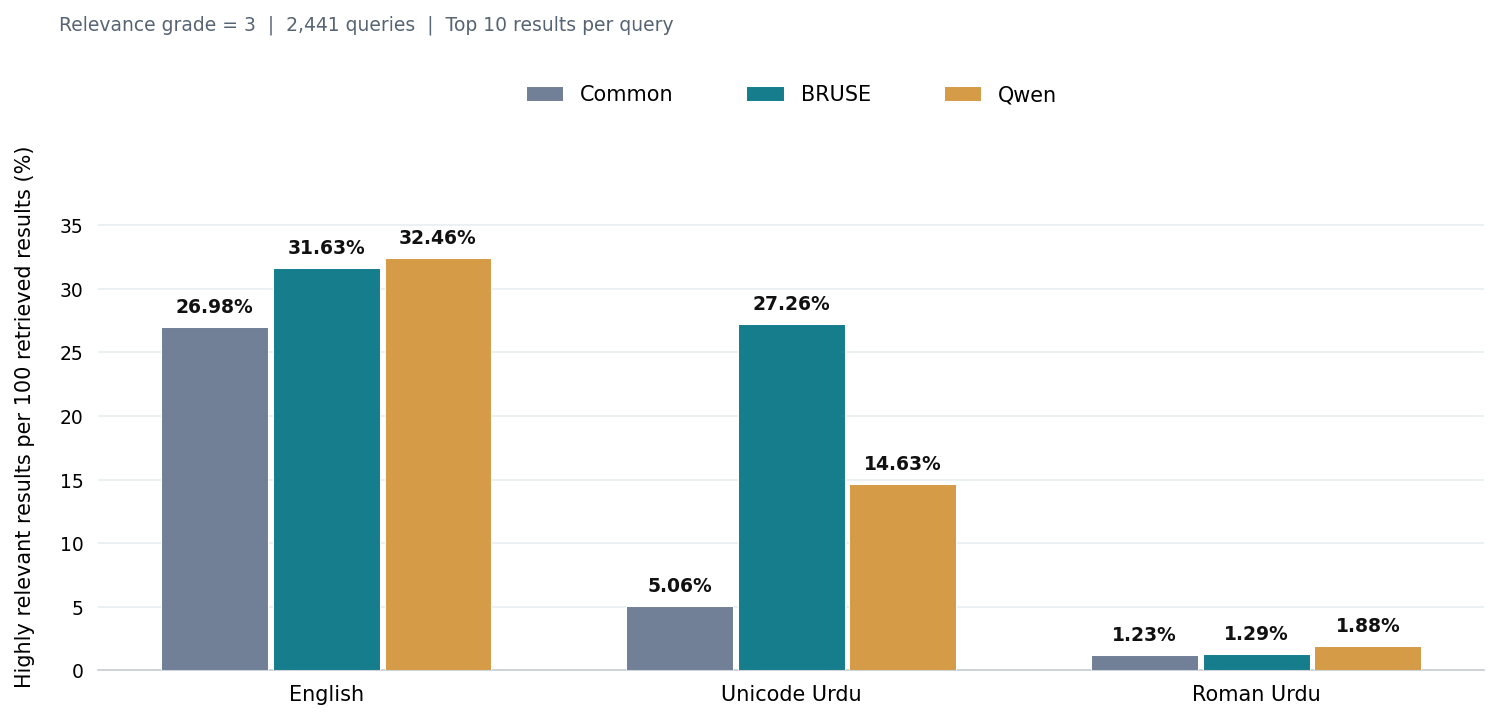


FILES CREATED:
F:\Eclipse\EclipseHome\BRUSE_TEST\brave search work\Grade3_Language_Figure\BRUSE_Grade3_Language_Retrieval_600dpi.png
F:\Eclipse\EclipseHome\BRUSE_TEST\brave search work\Grade3_Language_Figure\BRUSE_Grade3_Language_Retrieval_Vector.svg
F:\Eclipse\EclipseHome\BRUSE_TEST\brave search work\Grade3_Language_Figure\BRUSE_Grade3_Language_Retrieval_Vector.pdf

DONE: Figure generated from Excel source data.


In [ ]:
### Cell_7 
###This was added later due to some issue
###It generates Fig 12 of paper



from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. INPUT / OUTPUT PATHS
# ============================================================

INPUT_FILE = Path(
    r"F:\Eclipse\EclipseHome\BRUSE_TEST\brave search work\BSUE_Final_Three_Way_Comparison.xlsx"
)

SHEET_NAME = "Unified_Ranked_Results"

OUTPUT_DIR = INPUT_FILE.parent / "Grade3_Language_Figure"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_NAME = "BRUSE_Grade3_Language_Retrieval"

# ============================================================
# 2. READ ORIGINAL EXCEL DATA
# ============================================================

df = pd.read_excel(
    INPUT_FILE,
    sheet_name=SHEET_NAME,
    engine="openpyxl"
)

df.columns = df.columns.astype(str).str.strip()

required_columns = [
    "input_excel_row",
    "condition",
    "brave_rank",
    "llm_grade",
    "English_flag",
    "Unicode_Urdu_script_flag",
    "Roman_Urdu_flag"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns in Excel: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# ============================================================
# 3. NORMALIZE CONDITION NAMES
# ============================================================

# Supports historical BSUE labels in older Excel files,
# but uses BRUSE exclusively in the chart and output.

condition_mapping = {
    "common": "Common",
    "bruse_query2": "BRUSE",
    "bsue_query2": "BRUSE",
    "qwen_expanded": "Qwen",
    "qwen": "Qwen",
    "qwen-7b": "Qwen",
    "qwen2.5-7b-instruct": "Qwen"
}

df["condition"] = (
    df["condition"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(condition_mapping)
)

if df["condition"].isna().any():
    raise ValueError(
        "Unknown condition names found in Excel. "
        "Check the condition column."
    )

conditions = ["Common", "BRUSE", "Qwen"]

# ============================================================
# 4. VALIDATE THE RETRIEVAL DATA
# ============================================================

df["llm_grade"] = pd.to_numeric(
    df["llm_grade"], errors="raise"
)

df["brave_rank"] = pd.to_numeric(
    df["brave_rank"], errors="raise"
)

if df["llm_grade"].isna().any():
    raise ValueError("Missing relevance grades found.")

if not df["llm_grade"].isin([0, 1, 2, 3]).all():
    raise ValueError("Relevance grades must be 0, 1, 2 or 3.")

if not df["brave_rank"].between(1, 10).all():
    raise ValueError("Brave ranks must be between 1 and 10.")

if df.duplicated(
    ["condition", "input_excel_row", "brave_rank"]
).any():
    raise ValueError(
        "Duplicate query-condition-rank records found."
    )

expected_queries = 2441
expected_top_k = 10

for condition in conditions:

    subset = df[df["condition"] == condition]

    query_count = subset["input_excel_row"].nunique()
    result_count = len(subset)

    print(
        f"{condition}: "
        f"{query_count:,} queries, "
        f"{result_count:,} results"
    )

    assert query_count == expected_queries, (
        f"{condition}: Expected {expected_queries} queries, "
        f"found {query_count}."
    )

    assert result_count == expected_queries * expected_top_k, (
        f"{condition}: Expected "
        f"{expected_queries * expected_top_k} results, "
        f"found {result_count}."
    )

    rank_counts = subset.groupby(
        "input_excel_row"
    )["brave_rank"].nunique()

    assert (rank_counts == expected_top_k).all(), (
        f"{condition}: Some queries do not have 10 unique ranks."
    )

query_sets = [
    set(
        df.loc[
            df["condition"] == condition,
            "input_excel_row"
        ]
    )
    for condition in conditions
]

assert query_sets[0] == query_sets[1] == query_sets[2], (
    "The three conditions do not contain identical query IDs."
)

print("\nPASS: All three conditions are aligned.")

# ============================================================
# 5. NORMALIZE LANGUAGE FLAGS
# ============================================================

language_columns = {
    "English": "English_flag",
    "Unicode Urdu": "Unicode_Urdu_script_flag",
    "Roman Urdu": "Roman_Urdu_flag"
}

def normalize_flag(series):

    normalized = (
        series.astype("string")
        .str.strip()
        .str.lower()
    )

    valid_true = {"1", "1.0", "true", "yes", "y"}
    valid_false = {"0", "0.0", "false", "no", "n"}

    invalid = ~normalized.isin(valid_true | valid_false)

    if invalid.any():
        raise ValueError(
            "Invalid or missing language flags: "
            f"{series[invalid].unique().tolist()[:10]}"
        )

    return normalized.isin(valid_true)

for col in language_columns.values():
    df[col] = normalize_flag(df[col])

# ============================================================
# 6. CALCULATE GRADE-3 YIELD FROM EXCEL
# ============================================================

df["is_grade3"] = df["llm_grade"].eq(3)

results = []

for language, flag_col in language_columns.items():

    for condition in conditions:

        subset = df[df["condition"] == condition]

        denominator = len(subset)

        grade3_count = (
            subset["is_grade3"] & subset[flag_col]
        ).sum()

        percentage = (
            grade3_count / denominator * 100
        )

        results.append({
            "Language": language,
            "Condition": condition,
            "Grade3_Count": int(grade3_count),
            "Total_Results": denominator,
            "Percentage": percentage
        })

summary = pd.DataFrame(results)

pivot = summary.pivot(
    index="Language",
    columns="Condition",
    values="Percentage"
).reindex(
    index=list(language_columns),
    columns=conditions
)

print("\nGRADE-3 LANGUAGE-WISE RETRIEVAL YIELD (%)")
print(pivot.round(2).to_string())

print("\nUNDERLYING COUNTS")
print(summary.to_string(index=False))

summary.to_csv(
    OUTPUT_DIR / "Grade3_Language_Summary.csv",
    index=False
)

# ============================================================
# 7. ORIGINAL FIGURE COLORS
# ============================================================

COLORS = {
    "Common": "#718096",
    "BRUSE":  "#167D8D",
    "Qwen":   "#D59B46"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 9,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

# ============================================================
# 8. CREATE GROUPED BAR CHART
# ============================================================

fig, ax = plt.subplots(
    figsize=(10.5, 5.3),
    dpi=150
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

languages = list(language_columns)
x = np.arange(len(languages))

width = 0.23

offsets = {
    "Common": -width,
    "BRUSE": 0,
    "Qwen": width
}

for condition in conditions:

    values = pivot[condition].to_numpy()

    bars = ax.bar(
        x + offsets[condition],
        values,
        width,
        label=condition,
        color=COLORS[condition],
        edgecolor="white",
        linewidth=0.5,
        zorder=3
    )

    for bar, value in zip(bars, values):

        ax.annotate(
            f"{value:.2f}%",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color="#111111",
            clip_on=False
        )

# ============================================================
# 9. AXES, LEGEND AND ANNOTATION
# ============================================================

ax.set_xticks(x)
ax.set_xticklabels(languages)

ax.set_ylabel(
    "Highly relevant results per 100 retrieved results (%)",
    labelpad=12
)

max_value = pivot.to_numpy().max()

upper_limit = max(39, np.ceil((max_value + 5) / 5) * 5)

ax.set_ylim(0, upper_limit)
ax.set_yticks(np.arange(0, upper_limit, 5))

ax.grid(
    axis="y",
    color="#E8EDF1",
    linewidth=0.5,
    alpha=0.35,
    zorder=0
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#C5CDD3")

ax.tick_params(axis="both", length=0, pad=7)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.075),
    ncol=3,
    frameon=False,
    columnspacing=3.5,
    handlelength=1.8
)

fig.text(
    0.075, 0.975,
    "Relevance grade = 3  |  "
    f"{expected_queries:,} queries  |  "
    "Top 10 results per query",
    ha="left",
    va="top",
    fontsize=9,
    color="#566474"
)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.15,
    top=0.79
)

# ============================================================
# 10. EXPORT PUBLICATION-QUALITY FILES
# ============================================================

png_path = OUTPUT_DIR / f"{OUTPUT_NAME}_600dpi.png"
svg_path = OUTPUT_DIR / f"{OUTPUT_NAME}_Vector.svg"
pdf_path = OUTPUT_DIR / f"{OUTPUT_NAME}_Vector.pdf"

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.12
)

fig.savefig(
    svg_path,
    bbox_inches="tight",
    pad_inches=0.12
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.12
)

plt.show()
plt.close(fig)

print("\nFILES CREATED:")
print(png_path)
print(svg_path)
print(pdf_path)

print("\nDONE: Figure generated from Excel source data.")
